# Báo cáo Quý — Lượt bill, Giá trị TB bill, Khung giờ mua sắm

| # | Chỉ số | So sánh |
|---|---|---|
| 1 | Tổng lượt bill kỳ chính | Quý trước & cùng kỳ năm trước |
| 2 | Giá trị trung bình / bill | Quý trước & cùng kỳ năm trước |
| 3 | Khung giờ / ngày trong tuần khách tập trung mua sắm | Quý trước |
| 4 | Bill theo nhãn hàng AP / PIE / FLD (số bill, tỷ lệ, tổ hợp, giá trị TB) | Quý trước & cùng kỳ năm trước |
| 5 | Phân tích bill: theo ngày / thứ / khung giờ, giá trị TB tổng & từng hiệu, % bill Anamai–Bonjour | Quý trước & cùng kỳ năm trước |

Mục 1–2: mỗi kỳ (cùng kỳ, quý trước, quý chính) là 1 cột; nhãn ghi **% đạt** của quý chính so với từng kỳ, nét đứt = mức quý chính. Lượt bill không hiện số lượng; giá trị TB bill hiện giá trị (triệu đồng). Mục 3: cột % đạt từ trục 0%, nét đứt = 100%.

**Nguồn dữ liệu:** file thô `Baocao_BanHang_<từ>_<đến>.csv` (tải bằng `01.Data_Download` → mục *Bán hàng - BC_CTBH_Size*).
Parquet `01.System_sales` đã gộp theo mặt hàng nên **không còn số chứng từ / giờ bán / tổng tiền bill** → notebook đọc file thô
qua `Quarter_Bill_Data.py` (dùng lại `robust_read_csv`, `extract_ma_ch` của `Process_Sales.py`) và lưu cache 1 dòng/bill vào
`04.Output/Report_Quarter/Bill_Cache/`. Đã đọc 1 lần thì sau đó có thể chuyển/xoá file thô.

**Định nghĩa**
- **1 bill** = 1 `SoChungTu` có ít nhất 1 dòng *Bán* hợp lệ (loại Bao Bì, Đồng Phục, Dv In Theu, Khác — cùng logic `Process_Sales.py`). *Bán phiếu tặng* (chứng từ `-PT`) không tính.
- Mặc định loại bill `Tongtien ≤ 0` (đổi hàng bù trừ, không phát sinh tiền) — xem `BO_BILL_KHONG_TIEN`.
- **Giá trị bill** = `Tongtien` của chứng từ (khách thực trả, đã trừ Sale %, CK VIP). Giá trị TB = Σ Tongtien / số bill.
- **Khung giờ / thứ**: tỷ trọng % bill. Theo thứ dùng *bình quân bill/ngày của thứ đó* để không bị lệch do quý có 13 hay 14 ngày Thứ 2...

> **Cần đủ dữ liệu thô 9 tháng**: quý chính, quý trước, cùng kỳ năm trước (vd Q3.2026: 04→09/2026 và 07→09/2025). Ô *Nạp dữ liệu* sẽ báo tháng nào còn thiếu.

In [1]:
# ============ CẤU HÌNH ============
KY_CHINH = "Q3.2026"          # quý cần báo cáo

# Thư mục chứa file thô Baocao_BanHang_*.csv (có thể thêm thư mục khác)
RAW_DIRS_EXTRA = []           # vd [r"D:\Tai_ve\BanHang_2025"]

CHI_CH_CHUNG = False          # True = chỉ so các cửa hàng có bán ở CẢ 2 kỳ (like-for-like)
BO_BILL_KHONG_TIEN = True     # True = loại bill Tongtien <= 0 (bill đổi hàng bù trừ, không phát sinh tiền)
DOC_LAI_TAT_CA = False        # True = đọc lại toàn bộ file thô (bỏ qua danh sách đã đọc)
LUU_KET_QUA = True            # lưu PNG + Excel vào 04.Output/Report_Quarter/<KY_CHINH>

In [2]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

sys.path.insert(0, os.path.abspath(""))                    # 03.Projects/Report_Quarter
import Quarter_Bill_Data as qb
import Get_Paths

KY_TRUOC = qb.previous_quarter(KY_CHINH)
CUNG_KY = qb.same_quarter_last_year(KY_CHINH)
RAW_DIRS = [Get_Paths.nguon_ban_le] + RAW_DIRS_EXTRA
OUT_DIR = os.path.join(qb.OUTPUT_DIR, KY_CHINH)
os.makedirs(OUT_DIR, exist_ok=True)

# Màu theo KỲ (giữ cố định trong mọi biểu đồ)
MAU = {KY_CHINH: "#2a78d6", KY_TRUOC: "#eb6834", CUNG_KY: "#1baf7a"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.family": ["Segoe UI", "Arial", "DejaVu Sans"], "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlecolor": INK, "figure.dpi": 110, "savefig.dpi": 160,
})
pct = lambda v, d=1: f"{v:.{d}f}".replace(".", ",") + "%"


def co_the_ghi(path):
    # False (kèm cảnh báo) nếu file đang mở trong Excel -> notebook chạy tiếp, không dừng
    if not os.path.exists(path):
        return True
    khoa = os.path.join(os.path.dirname(path), "~$" + os.path.basename(path))   # Excel tạo file này khi đang mở
    try:
        if os.path.exists(khoa):
            raise PermissionError
        os.rename(path, path + ".tmp"); os.rename(path + ".tmp", path)          # file bị khoá thì không đổi tên được
        return True
    except PermissionError:
        print(f"⚠️  Không ghi được {os.path.basename(path)} (file đang mở trong Excel). Đóng file rồi chạy lại ô này.")
        return False


print(f"Kỳ chính {KY_CHINH} | Quý trước {KY_TRUOC} | Cùng kỳ {CUNG_KY}")
print("Thư mục kết quả:", OUT_DIR)

Kỳ chính Q3.2026 | Quý trước Q2.2026 | Cùng kỳ Q3.2025
Thư mục kết quả: D:\AnPhuocGroup\AnPhuoc_Data\01.Python_Projects\04.Output\Report_Quarter\Q3.2026


## Nạp dữ liệu

In [3]:
qb.update_bill_cache(RAW_DIRS, force=DOC_LAI_TAT_CA)
print()
bills = qb.load_quarters([KY_CHINH, KY_TRUOC, CUNG_KY])
if BO_BILL_KHONG_TIEN:
    n0 = len(bills); bills = bills[bills["Tongtien"] > 0].copy()
    print(f"\nĐã loại {n0 - len(bills):,} bill Tongtien <= 0 (đổi hàng bù trừ)")
bills["Thang_trong_quy"] = (bills["Month"] - 1) % 3 + 1
thieu = [q for q in (KY_CHINH, KY_TRUOC, CUNG_KY) if q not in set(bills["Quarter"])]
if thieu:
    print(f"\n⚠️  CHƯA CÓ DỮ LIỆU: {', '.join(thieu)} — tải file thô Baocao_BanHang các tháng này rồi chạy lại ô này.")

Tìm thấy 9 file thô, cần đọc mới: 0

  Q3.2026 | 07/2026:    73,095 bill | 01/07 -> 31/07
  Q3.2026 | 08/2026:    77,697 bill | 01/08 -> 31/08
  Q3.2026 | 09/2026:    69,842 bill | 01/09 -> 30/09


  Q2.2026 | 04/2026:    80,447 bill | 01/04 -> 30/04
  Q2.2026 | 05/2026:    70,623 bill | 01/05 -> 31/05
  Q2.2026 | 06/2026:    74,171 bill | 01/06 -> 30/06
  Q3.2025 | 07/2025:    75,733 bill | 01/07 -> 31/07
  Q3.2025 | 08/2025:    82,857 bill | 01/08 -> 31/08


  Q3.2025 | 09/2025:    71,196 bill | 01/09 -> 30/09



Đã loại 37,222 bill Tongtien <= 0 (đổi hàng bù trừ)


In [4]:
def bo_loc_ch_chung(df, q_a, q_b):
    # Giữ các cửa hàng có bill ở cả 2 quý (khi CHI_CH_CHUNG = True)
    d = df[df["Quarter"].isin([q_a, q_b])]
    if not CHI_CH_CHUNG:
        return d
    ch = set(d.loc[d["Quarter"] == q_a, "Store_code"]) & set(d.loc[d["Quarter"] == q_b, "Store_code"])
    return d[d["Store_code"].isin(ch)]


def chi_so(df, by=None):
    # Số bill, tổng tiền, giá trị TB bill theo Quarter (+ by)
    keys = ["Quarter"] + ([by] if by else [])
    g = df.groupby(keys).agg(So_bill=("SoChungTu", "size"), Tong_tien=("Tongtien", "sum")).reset_index()
    g["TB_bill"] = g["Tong_tien"] / g["So_bill"]
    return g


def so_sanh(metric, ky_ss, by=None):
    # % đạt của KY_CHINH so với ky_ss (theo tổng hoặc theo cột by)
    g = chi_so(bo_loc_ch_chung(bills, KY_CHINH, ky_ss), by)
    idx = [by] if by else []
    a = g[g["Quarter"] == KY_CHINH].set_index(idx)[metric] if by else g.loc[g["Quarter"] == KY_CHINH, metric].sum()
    b = g[g["Quarter"] == ky_ss].set_index(idx)[metric] if by else g.loc[g["Quarter"] == ky_ss, metric].sum()
    return a / b * 100 if not by else (a / b * 100).dropna()


def ve_dat(ax, x, values, mau, width, labels=True, horizontal=False):
    # Cột % đạt mọc từ cùng 1 trục 0%; nhãn 'xx%' nằm trong đầu cột (không bị đường 100% cắt)
    vals = np.asarray(values, dtype=float)
    if horizontal:
        bars = ax.barh(x, vals, height=width, color=mau, edgecolor="white", linewidth=1)
    else:
        bars = ax.bar(x, vals, width=width, color=mau, edgecolor="white", linewidth=1)
    if labels:
        for bar, v in zip(bars, vals):
            if np.isnan(v):
                continue
            if horizontal:
                ax.annotate(pct(v), (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                            xytext=(-5, 0), textcoords="offset points",
                            va="center", ha="right", fontsize=9, color="white", fontweight="bold")
            else:
                ax.annotate(pct(v), (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                            xytext=(0, -5), textcoords="offset points",
                            ha="center", va="top", fontsize=9, color="white", fontweight="bold")
    return bars


def trang_tri_truc(ax, horizontal=False):
    # Trục bắt đầu 0%, đường nét đứt 100% = mốc bằng kỳ so sánh
    fmt = mtick.FuncFormatter(lambda v, _: f"{v:.0f}%")
    get_lim, set_lim = (ax.get_xlim, ax.set_xlim) if horizontal else (ax.get_ylim, ax.set_ylim)
    set_lim(0, max(get_lim()[1], 100) * 1.12)
    if horizontal:
        ax.axvline(100, color=INK, lw=1.4, ls="--")
        ax.annotate("100%", (100, 1), xycoords=("data", "axes fraction"), xytext=(0, 3),
                    textcoords="offset points", ha="center", va="bottom", fontsize=8.5, color=INK, fontweight="bold")
        ax.xaxis.set_major_formatter(fmt); ax.grid(axis="x", color=GRID, lw=0.8)
    else:
        ax.axhline(100, color=INK, lw=1.4, ls="--")
        ax.annotate("100%", (1, 100), xycoords=("axes fraction", "data"), xytext=(3, 0),
                    textcoords="offset points", ha="left", va="center", fontsize=8.5, color=INK, fontweight="bold")
        ax.yaxis.set_major_formatter(fmt); ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)



KY_ALL = [CUNG_KY, KY_TRUOC, KY_CHINH]          # thứ tự thời gian: cùng kỳ -> quý trước -> kỳ chính
tien = lambda v: f"{v / 1e6:.2f}".replace(".", ",") + " tr"


def gia_tri_ky(metric, by=None):
    # Giá trị metric của 3 kỳ (index = nhóm, cột = KY_ALL); CHI_CH_CHUNG: chỉ CH có bán ở cả 3 kỳ
    d = bills[bills["Quarter"].isin(KY_ALL)]
    if CHI_CH_CHUNG:
        ch = set.intersection(*[set(d.loc[d["Quarter"] == q, "Store_code"]) for q in KY_ALL])
        d = d[d["Store_code"].isin(ch)]
    g = chi_so(d, by)
    if by is None:
        return g.set_index("Quarter")[[metric]].T.reindex(columns=KY_ALL).set_axis(["Toàn hệ thống"])
    return g.pivot(index=by, columns="Quarter", values=metric).reindex(columns=KY_ALL)


def ve_3_ky(ax, df, metric, horizontal=False, w=0.26, step=None):
    # Mỗi kỳ 1 cột; nét đứt = mức Q3.2026 trong nhóm; nhãn % đạt cạnh cột kỳ chính
    hien_gt = metric == "TB_bill"
    n = len(df)
    step = step or w                              # khoảng cách giữa các cột trong nhóm
    nhieu = n >= 5                                # nhiều nhóm -> cột hẹp: chữ nhỏ, bỏ chữ "tr"
    fs = 7 if nhieu else 8.5
    fmt_gt = (lambda v: f"{v / 1e6:.2f}".replace(".", ",")) if nhieu else tien
    for j, k in enumerate(KY_ALL):
        pos = np.arange(n) + (j - 1) * step
        bars = (ax.barh if horizontal else ax.bar)(pos, df[k].values, w, color=MAU[k], edgecolor="white", linewidth=1)
        if hien_gt:
            for b, v in zip(bars, df[k].values):
                if np.isnan(v):
                    continue
                if horizontal:
                    ax.annotate(fmt_gt(v), (b.get_width(), b.get_y() + b.get_height() / 2), xytext=(-4, 0),
                                textcoords="offset points", ha="right", va="center", fontsize=8, color="white", fontweight="bold")
                else:
                    ax.annotate(fmt_gt(v), (b.get_x() + b.get_width() / 2, b.get_height()), xytext=(0, -5),
                                textcoords="offset points", ha="center", va="top", fontsize=fs, color="white", fontweight="bold")
    for i, (nhom, row) in enumerate(df.iterrows()):
        v = row[KY_CHINH]
        if np.isnan(v):
            continue
        p_truoc, p_ck = row[KY_CHINH] / row[KY_TRUOC] * 100, row[KY_CHINH] / row[CUNG_KY] * 100
        if horizontal:
            ax.vlines(v, i - step - w / 2, i + step + w / 2, colors=INK, linestyles="--", lw=1.2)
            ax.annotate(f"{pct(p_truoc)} so {KY_TRUOC}  ·  {pct(p_ck)} so {CUNG_KY}",
                        (max(row.max(), v), i + step), xytext=(6, 0), textcoords="offset points",
                        ha="left", va="center", fontsize=8.5, color=INK)
        else:
            ax.hlines(v, i - step - w / 2, i + step + w / 2, colors=INK, linestyles="--", lw=1.2)
            # nhiều nhóm -> nhãn gọn 1 dòng "so quý trước | so cùng kỳ" (chú thích ở góc trên phải)
            nhan = f"{pct(p_truoc)} | {pct(p_ck)}" if nhieu else f"{pct(p_truoc)} so {KY_TRUOC}\n{pct(p_ck)} so {CUNG_KY}"
            ax.annotate(nhan, (i if nhieu else i + step, max(row.max(), v)), xytext=(0, 6), textcoords="offset points",
                        ha="center", va="bottom", fontsize=fs + (0.5 if nhieu else 0), color=INK, fontweight="bold")
    if nhieu and not horizontal:
        ax.text(1, 1.02, f"Nhãn: % đạt so {KY_TRUOC} | so {CUNG_KY}", transform=ax.transAxes,
                ha="right", va="bottom", fontsize=8.5, color=INK2)
    vmax = np.nanmax(df.values)
    if horizontal:
        ax.set_xlim(0, vmax * 1.55); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
        ax.set_yticks(range(n), df.index); ax.invert_yaxis()
    else:
        ax.set_ylim(0, vmax * 1.3); ax.set_yticks([]); ax.spines["left"].set_visible(False)
        ax.set_xticks(range(n), df.index)


def bieu_do_chi_so(metric, tieu_de, ten_file):
    fig = plt.figure(figsize=(13, 10.5))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.35], width_ratios=[1, 1.7], hspace=0.3, wspace=0.12)

    # (a) Toàn hệ thống: 3 cột, tên kỳ dưới mỗi cột
    ax = fig.add_subplot(gs[0, 0])
    ve_3_ky(ax, gia_tri_ky(metric), metric, w=0.22, step=0.32)
    ax.set_xticks([(j - 1) * 0.32 for j in range(3)], KY_ALL)
    ax.set_title("Toàn hệ thống", loc="left")

    # (b) Theo tháng trong quý
    ax = fig.add_subplot(gs[0, 1])
    thang_chinh = {i: m for i, (_, m) in enumerate(qb.quarter_months(KY_CHINH), 1)}
    df = gia_tri_ky(metric, "Thang_trong_quy").reindex([1, 2, 3]).rename(index=lambda i: f"Tháng {thang_chinh[i]}")
    ve_3_ky(ax, df, metric)
    ax.set_title("Theo tháng (so với tháng tương ứng của từng kỳ)", loc="left")

    # (c) Theo vùng
    ax = fig.add_subplot(gs[1, :])
    vung = [v for v in bills.loc[bills["Quarter"] == KY_CHINH, "Region"].value_counts().index if v != "Không xác định"]
    ve_3_ky(ax, gia_tri_ky(metric, "Region").reindex(vung), metric, horizontal=True)
    ax.set_title("Theo vùng", loc="left")

    handles = [plt.Rectangle((0, 0), 1, 1, color=MAU[k]) for k in KY_ALL]
    handles.append(plt.Line2D([], [], color=INK, ls="--", lw=1.2))
    fig.legend(handles, KY_ALL + [f"Mức {KY_CHINH}"], loc="upper right", ncol=4, frameon=False,
               bbox_to_anchor=(0.98, 0.985))
    mo_ta = ("Số trong cột = giá trị trung bình 1 bill (triệu đồng). " if metric == "TB_bill" else "")
    mo_ta += f"Nhãn % = {KY_CHINH} đạt so với từng kỳ"
    mo_ta += " · Chỉ cửa hàng có bán ở cả 3 kỳ" if CHI_CH_CHUNG else ""
    fig.suptitle(tieu_de, x=0.02, y=0.99, ha="left", fontsize=15, fontweight="bold", color=INK)
    fig.text(0.02, 0.948, mo_ta, fontsize=9.5, color=INK2)
    if LUU_KET_QUA:
        fig.savefig(os.path.join(OUT_DIR, ten_file), bbox_inches="tight", facecolor="white")
    plt.show()

## Tóm tắt (bảng tham chiếu)

In [5]:
tong = chi_so(bills).set_index("Quarter").reindex([KY_CHINH, KY_TRUOC, CUNG_KY])
tom_tat = pd.DataFrame({
    "Chỉ số": ["Tổng lượt bill", "Giá trị TB / bill"],
    f"{KY_CHINH} đạt so với {KY_TRUOC}": [pct(so_sanh("So_bill", KY_TRUOC)), pct(so_sanh("TB_bill", KY_TRUOC))],
    f"{KY_CHINH} đạt so với {CUNG_KY}": [pct(so_sanh("So_bill", CUNG_KY)), pct(so_sanh("TB_bill", CUNG_KY))],
})
display(tom_tat)
display(tong.style.format({"So_bill": "{:,.0f}", "Tong_tien": "{:,.0f}", "TB_bill": "{:,.0f}"}))

,Chỉ số,Q3.2026 đạt so với Q2.2026,Q3.2026 đạt so với Q3.2025
0,Tổng lượt bill,"97,9%","96,4%"
1,Giá trị TB / bill,"101,8%","99,9%"


,So_bill,Tong_tien,TB_bill
Quarter,,,
Q3.2026,"208,699","415,141,075,090","1,989,186"
Q2.2026,"213,237","416,539,016,113","1,953,409"
Q3.2025,"216,503","431,309,842,507","1,992,166"


## 1. Tổng lượt bill

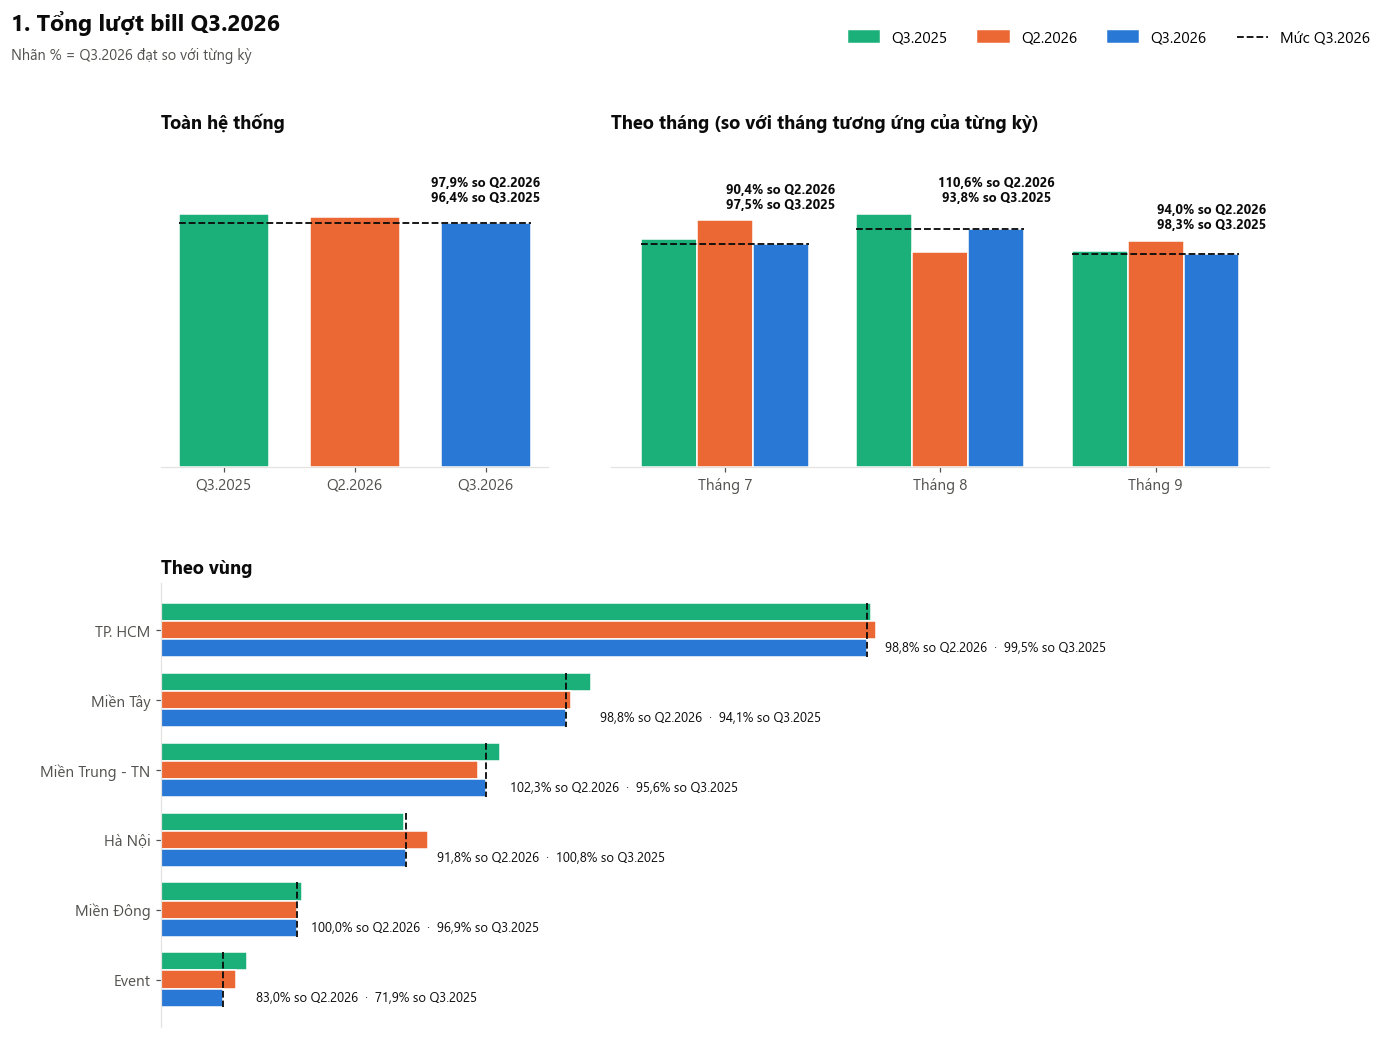

In [6]:
bieu_do_chi_so("So_bill", f"1. Tổng lượt bill {KY_CHINH}", "1_Luot_bill.png")

## 2. Giá trị trung bình bill

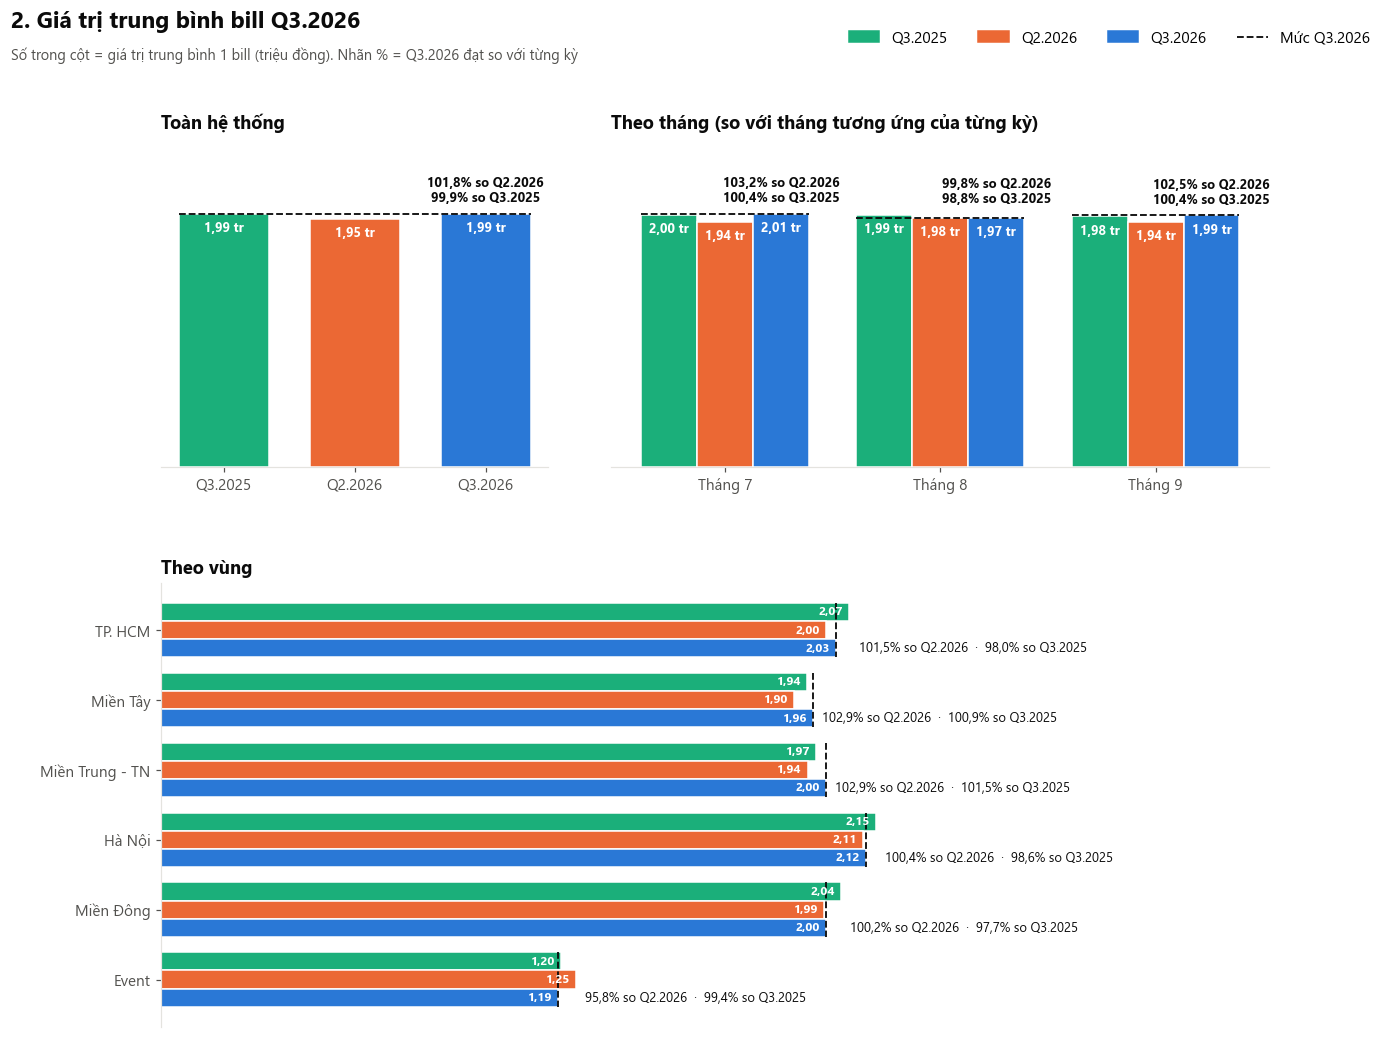

In [7]:
bieu_do_chi_so("TB_bill", f"2. Giá trị trung bình bill {KY_CHINH}", "2_Gia_tri_TB_bill.png")

## 3. Khung giờ / ngày khách tập trung mua sắm (so với quý trước)

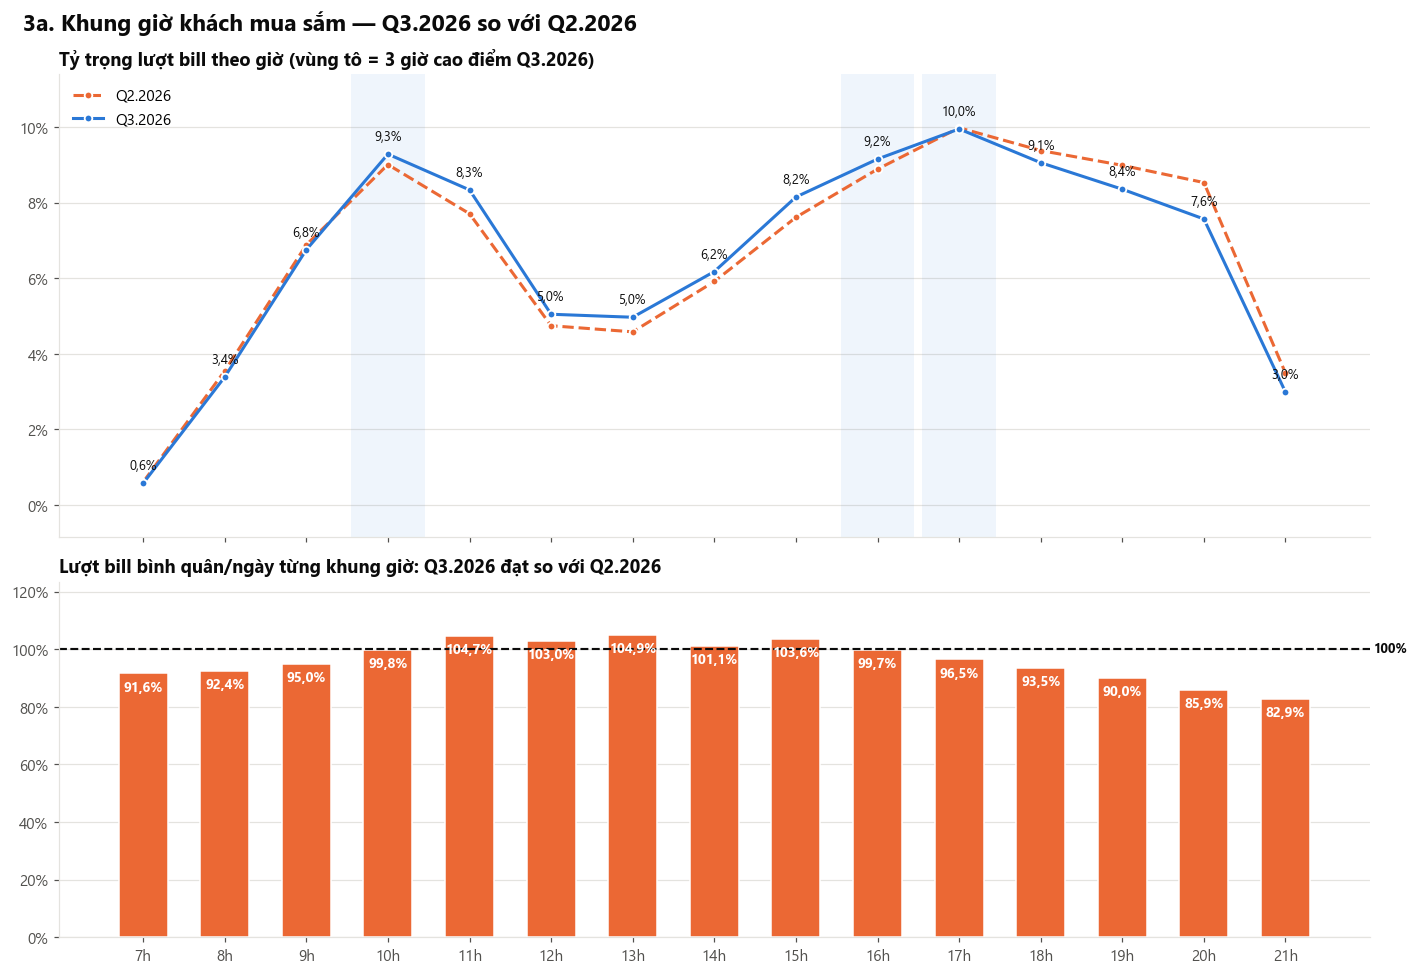

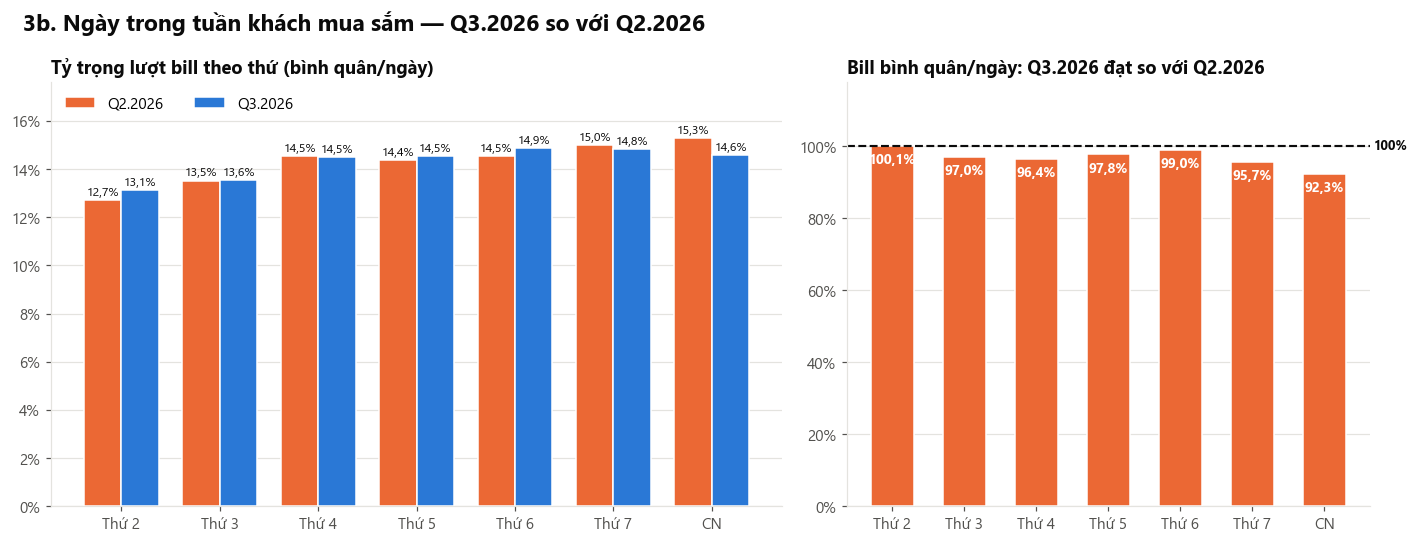

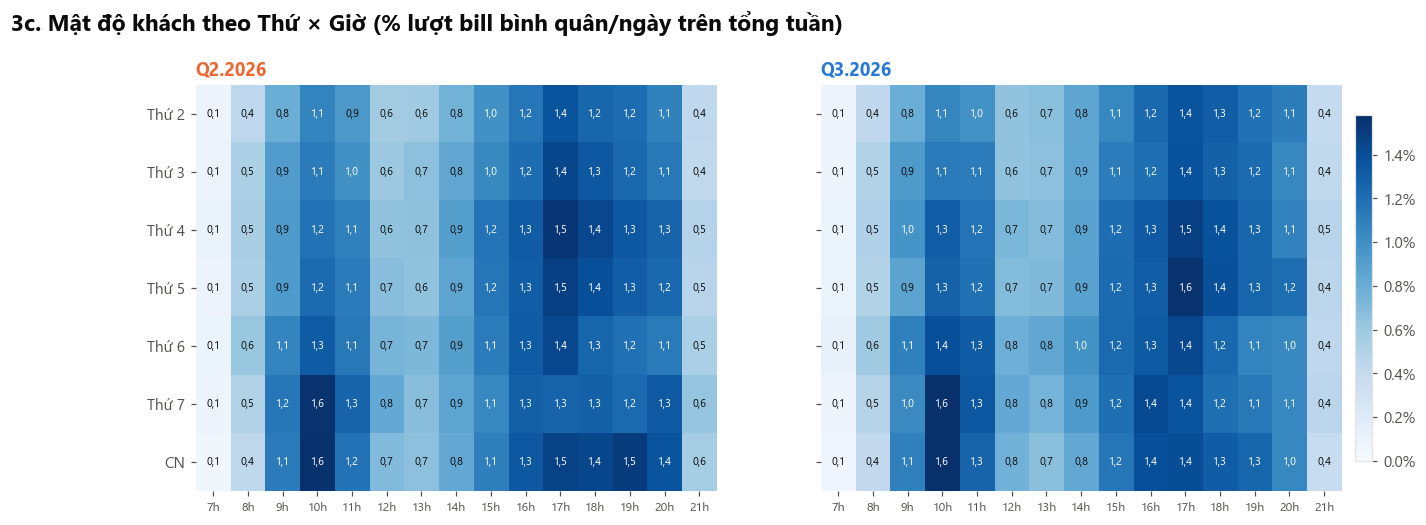

Top 10 khung Thứ × Giờ đông khách nhất Q3.2026:


,Thứ,Khung giờ,Tỷ trọng %,Tỷ trọng Q2.2026 %
0,Thứ 7,10h-11h,1.58,1.56
1,CN,10h-11h,1.58,1.56
2,Thứ 5,17h-18h,1.56,1.48
3,Thứ 4,17h-18h,1.48,1.54
4,Thứ 6,17h-18h,1.43,1.44
5,Thứ 7,16h-17h,1.42,1.29
6,CN,17h-18h,1.40,1.47
7,CN,16h-17h,1.39,1.34
8,Thứ 6,10h-11h,1.39,1.31
9,Thứ 5,18h-19h,1.39,1.39


In [8]:
d3 = bo_loc_ch_chung(bills, KY_CHINH, KY_TRUOC)
KY3 = [KY_TRUOC, KY_CHINH]

# Bình quân bill / ngày theo (Thứ, Giờ): chia cho số ngày của thứ đó trong quý
so_ngay_thu = d3.groupby(["Quarter", "Thu"])["Ngay"].nunique()
bq = (d3.groupby(["Quarter", "Thu", "Gio"]).size() / so_ngay_thu).rename("bq").reset_index()

def ty_trong(by):
    t = bq.groupby(["Quarter", by])["bq"].sum()
    return (t / t.groupby(level=0).transform("sum") * 100).unstack(0).reindex(columns=KY3).fillna(0)

tt_gio, tt_thu = ty_trong("Gio"), ty_trong("Thu")
gio_hien = tt_gio.index[(tt_gio.max(axis=1) >= 0.3)]          # bỏ giờ gần như không có bill
tt_gio = tt_gio.loc[gio_hien.min():gio_hien.max()]
# % đạt (bình quân bill/ngày) kỳ chính so với quý trước
dat_gio = (bq.groupby(["Quarter", "Gio"])["bq"].sum().unstack(0).reindex(tt_gio.index))
dat_gio = dat_gio[KY_CHINH] / dat_gio[KY_TRUOC] * 100
dat_thu = bq.groupby(["Quarter", "Thu"])["bq"].sum().unstack(0)
dat_thu = dat_thu[KY_CHINH] / dat_thu[KY_TRUOC] * 100

nhan_gio = [f"{h}h" for h in tt_gio.index]

# ---- 3a. Theo giờ ----
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9), height_ratios=[1.3, 1], sharex=True)
x = np.arange(len(tt_gio))
for k, ls in ((KY_TRUOC, "--"), (KY_CHINH, "-")):
    ax1.plot(x, tt_gio[k], ls, color=MAU[k], lw=2, marker="o", ms=5, label=k,
             markeredgecolor="white", markeredgewidth=1.2)
for xi, v in zip(x, tt_gio[KY_CHINH]):
    ax1.annotate(pct(v), (xi, v), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5, color=INK)
top3 = tt_gio[KY_CHINH].nlargest(3).index
for h in top3:
    ax1.axvspan(list(tt_gio.index).index(h) - 0.45, list(tt_gio.index).index(h) + 0.45, color=MAU[KY_CHINH], alpha=0.07, lw=0)
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax1.grid(axis="y", color=GRID); ax1.set_axisbelow(True); ax1.margins(y=0.15)
ax1.set_title(f"Tỷ trọng lượt bill theo giờ (vùng tô = 3 giờ cao điểm {KY_CHINH})", loc="left")
ax1.legend(frameon=False, loc="upper left")

ve_dat(ax2, x, dat_gio.values, MAU[KY_TRUOC], 0.6)
trang_tri_truc(ax2)
ax2.set_title(f"Lượt bill bình quân/ngày từng khung giờ: {KY_CHINH} đạt so với {KY_TRUOC}", loc="left")
ax2.set_xticks(x, nhan_gio)
fig.suptitle(f"3a. Khung giờ khách mua sắm — {KY_CHINH} so với {KY_TRUOC}", x=0.02, ha="left",
             fontsize=15, fontweight="bold", color=INK)
fig.tight_layout()
if LUU_KET_QUA:
    fig.savefig(os.path.join(OUT_DIR, "3a_Khung_gio.png"), bbox_inches="tight", facecolor="white")
plt.show()

# ---- 3b. Theo thứ ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), width_ratios=[1.4, 1])
x = np.arange(7); w = 0.38
for j, k in enumerate(KY3):
    bars = ax1.bar(x + (j - 0.5) * w, tt_thu[k].reindex(range(7)), w, color=MAU[k], label=k,
                   edgecolor="white", linewidth=1)
    for b in bars:
        ax1.annotate(pct(b.get_height()), (b.get_x() + b.get_width() / 2, b.get_height()),
                     xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color=INK)
ax1.set_xticks(x, qb.THU_VN)
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax1.grid(axis="y", color=GRID); ax1.set_axisbelow(True); ax1.legend(frameon=False, ncol=2, loc="upper left")
ax1.margins(y=0.15); ax1.set_title("Tỷ trọng lượt bill theo thứ (bình quân/ngày)", loc="left")

ve_dat(ax2, x, dat_thu.reindex(range(7)).values, MAU[KY_TRUOC], 0.6)
trang_tri_truc(ax2); ax2.set_xticks(x, qb.THU_VN)
ax2.set_title(f"Bill bình quân/ngày: {KY_CHINH} đạt so với {KY_TRUOC}", loc="left")
fig.suptitle(f"3b. Ngày trong tuần khách mua sắm — {KY_CHINH} so với {KY_TRUOC}", x=0.02, ha="left",
             fontsize=15, fontweight="bold", color=INK)
fig.tight_layout()
if LUU_KET_QUA:
    fig.savefig(os.path.join(OUT_DIR, "3b_Ngay_trong_tuan.png"), bbox_inches="tight", facecolor="white")
plt.show()

# ---- 3c. Bản đồ nhiệt Thứ x Giờ ----
hm = {}
for k in KY3:
    t = bq[bq["Quarter"] == k].pivot_table(index="Thu", columns="Gio", values="bq", aggfunc="sum")
    t = t.reindex(index=range(7), columns=tt_gio.index).fillna(0)
    hm[k] = t / t.values.sum() * 100
vmax = max(h.values.max() for h in hm.values())
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)
for ax, k in zip(axes, KY3):
    im = ax.imshow(hm[k].values, cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    for i in range(7):
        for j in range(hm[k].shape[1]):
            v = hm[k].values[i, j]
            ax.text(j, i, f"{v:.1f}".replace(".", ","), ha="center", va="center", fontsize=7,
                    color="white" if v > vmax * 0.6 else INK)
    ax.set_xticks(range(len(nhan_gio)), nhan_gio, fontsize=8); ax.set_yticks(range(7), qb.THU_VN)
    ax.set_title(k, loc="left", color=MAU[k])
    for s in ax.spines.values():
        s.set_visible(False)
cb = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.01)
cb.ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.1f}%"))
fig.suptitle("3c. Mật độ khách theo Thứ × Giờ (% lượt bill bình quân/ngày trên tổng tuần)", x=0.02, ha="left",
             fontsize=15, fontweight="bold", color=INK, y=1.02)
if LUU_KET_QUA:
    fig.savefig(os.path.join(OUT_DIR, "3c_Thu_x_Gio.png"), bbox_inches="tight", facecolor="white")
plt.show()

top = (hm[KY_CHINH].stack().rename("Tỷ trọng %").reset_index().sort_values("Tỷ trọng %", ascending=False).head(10))
top["Thứ"] = top["Thu"].map(dict(enumerate(qb.THU_VN))); top["Khung giờ"] = top["Gio"].map(lambda h: f"{h}h-{h + 1}h")
top[f"Tỷ trọng {KY_TRUOC} %"] = [hm[KY_TRUOC].loc[t, g] for t, g in zip(top["Thu"], top["Gio"])]
print(f"Top 10 khung Thứ × Giờ đông khách nhất {KY_CHINH}:")
display(top[["Thứ", "Khung giờ", "Tỷ trọng %", f"Tỷ trọng {KY_TRUOC} %"]].round(2).reset_index(drop=True))

## 4. Bill theo nhãn hàng: AP / PIE / FLD

Số bill CÓ từng nhãn:


Quarter,Q3.2025,Q2.2026,Q3.2026
Có AP,"144,931","142,280","139,352"
Có PIE,"89,751","90,483","87,620"
Có FLD,"14,000","13,104","12,731"


Tỷ lệ % bill có từng nhãn / tổng bill:


Quarter,Q3.2025,Q2.2026,Q3.2026
Có AP,66.9,66.7,66.8
Có PIE,41.5,42.4,42.0
Có FLD,6.5,6.1,6.1


Số bill theo tổ hợp nhãn:


...

Quarter,Q3.2025,Q2.2026,Q3.2026
To_hop,,,
Chỉ AP,53.0,52.4,52.9
Chỉ PIE,28.5,29.2,29.0
Chỉ FLD,4.1,3.6,3.8
AP + PIE,12.0,12.2,12.0
AP + FLD,1.4,1.6,1.4
PIE + FLD,0.4,0.5,0.5
AP + PIE + FLD,0.5,0.5,0.5


Giá trị TB bill theo tổ hợp (triệu đồng):


Quarter,Q3.2025,Q2.2026,Q3.2026
To_hop,,,
Chỉ AP,1.41,1.38,1.42
Chỉ PIE,2.48,2.40,2.45
Chỉ FLD,0.86,0.87,0.84
AP + PIE,3.55,3.46,3.51
AP + FLD,2.17,2.18,2.33
PIE + FLD,3.47,3.39,3.43
AP + PIE + FLD,5.53,5.18,5.24


Số sản phẩm TB / bill theo tổ hợp:


Quarter,Q3.2025,Q2.2026,Q3.2026
To_hop,,,
Chỉ AP,1.68,1.68,1.69
Chỉ PIE,1.50,1.51,1.47
Chỉ FLD,2.66,2.49,2.59
AP + PIE,3.53,3.53,3.55
AP + FLD,4.06,4.10,4.26
PIE + FLD,4.01,3.95,4.08
AP + PIE + FLD,6.86,6.68,6.78


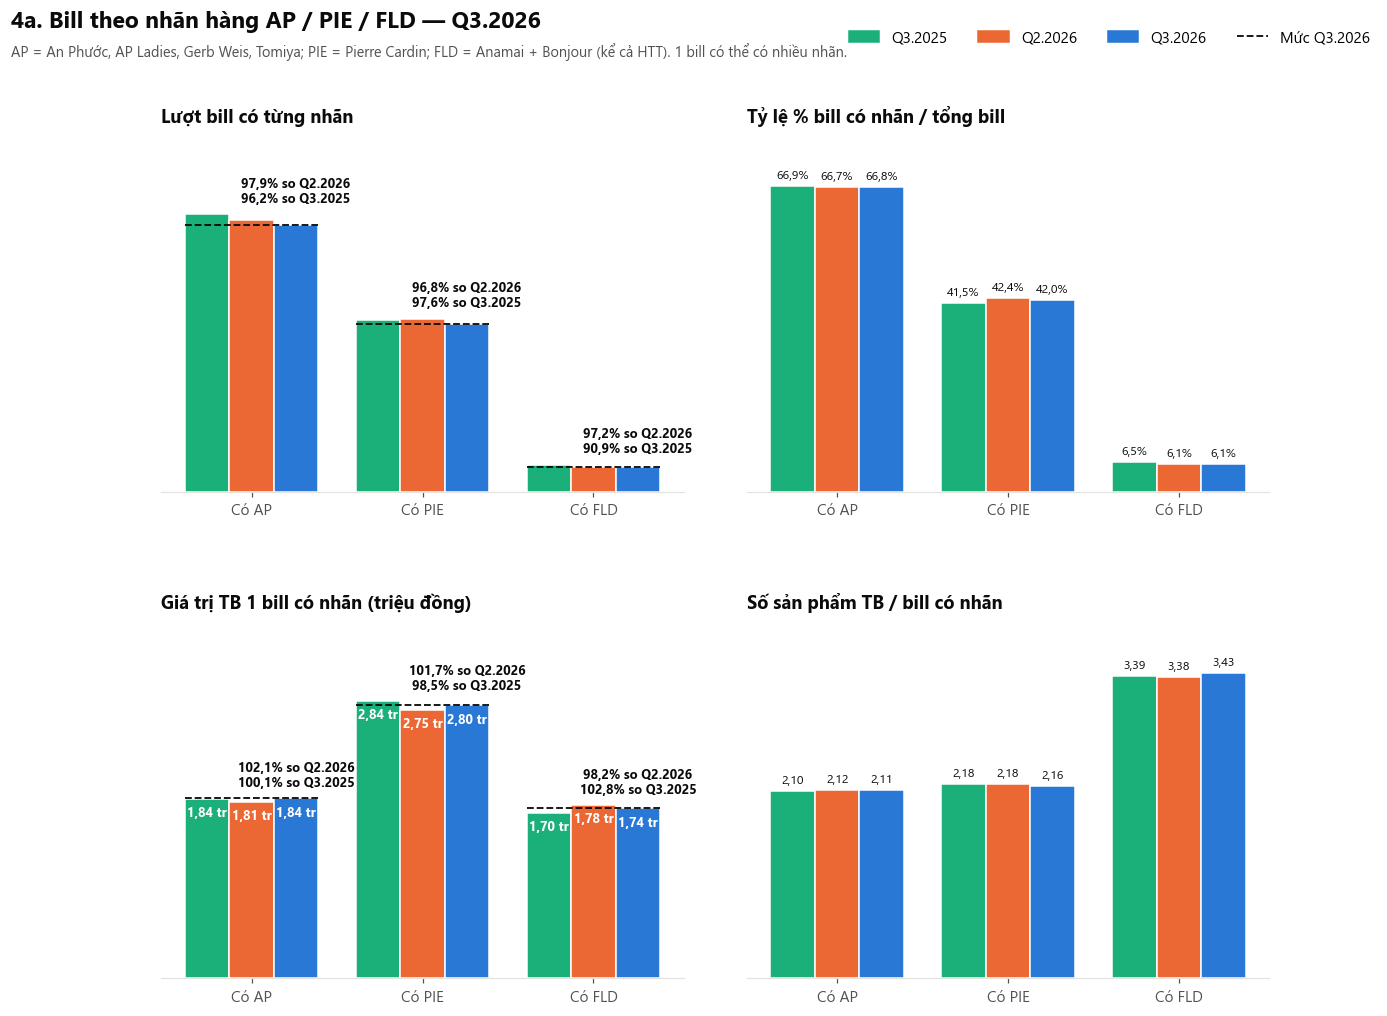

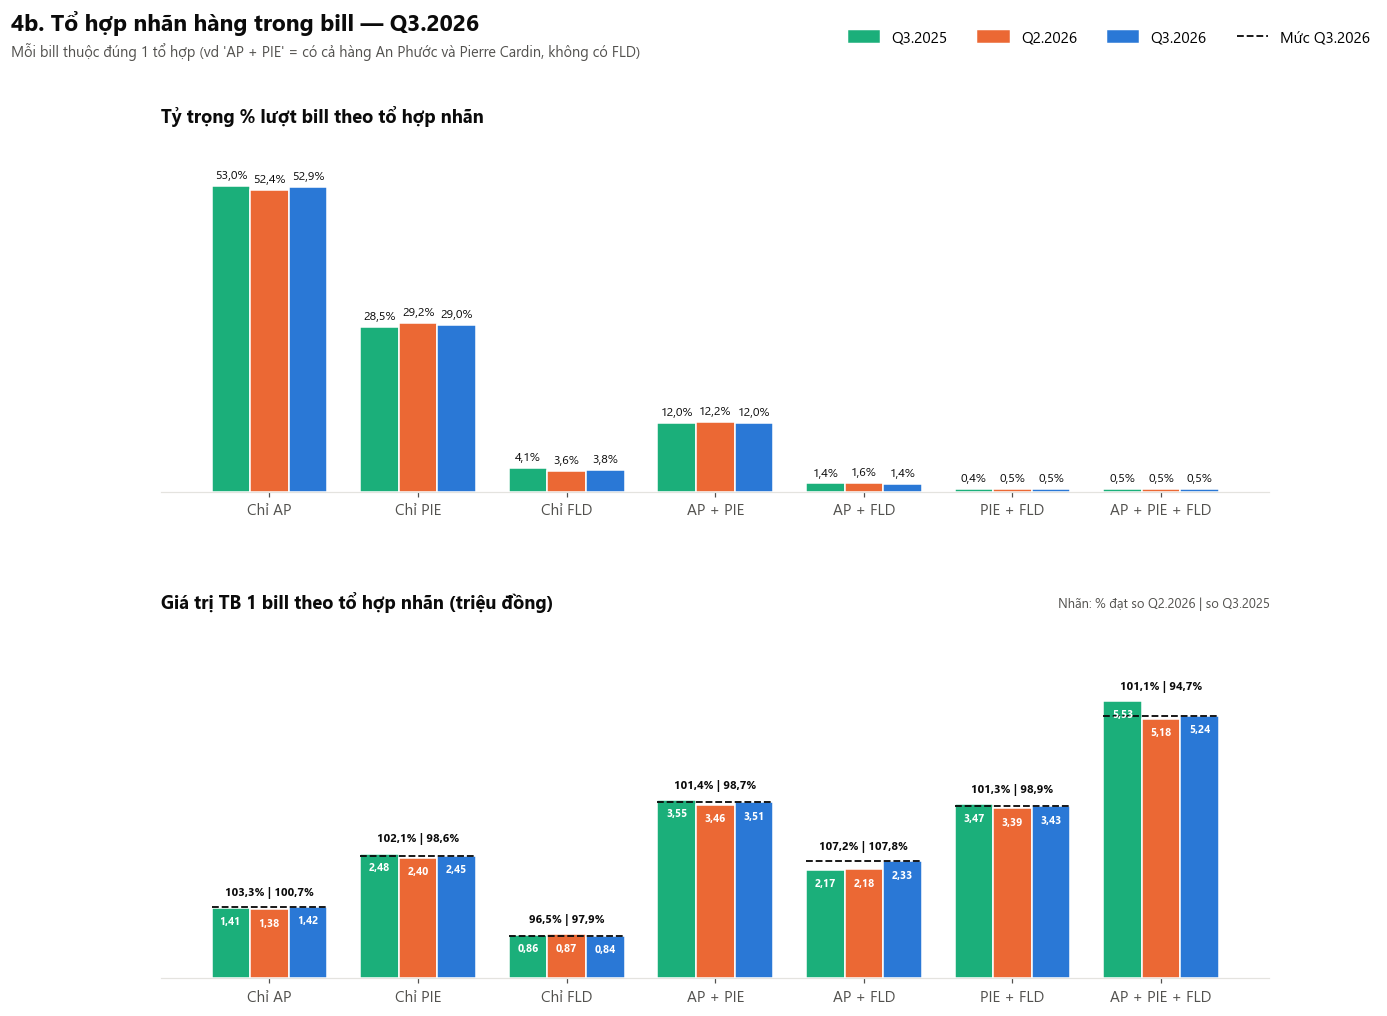

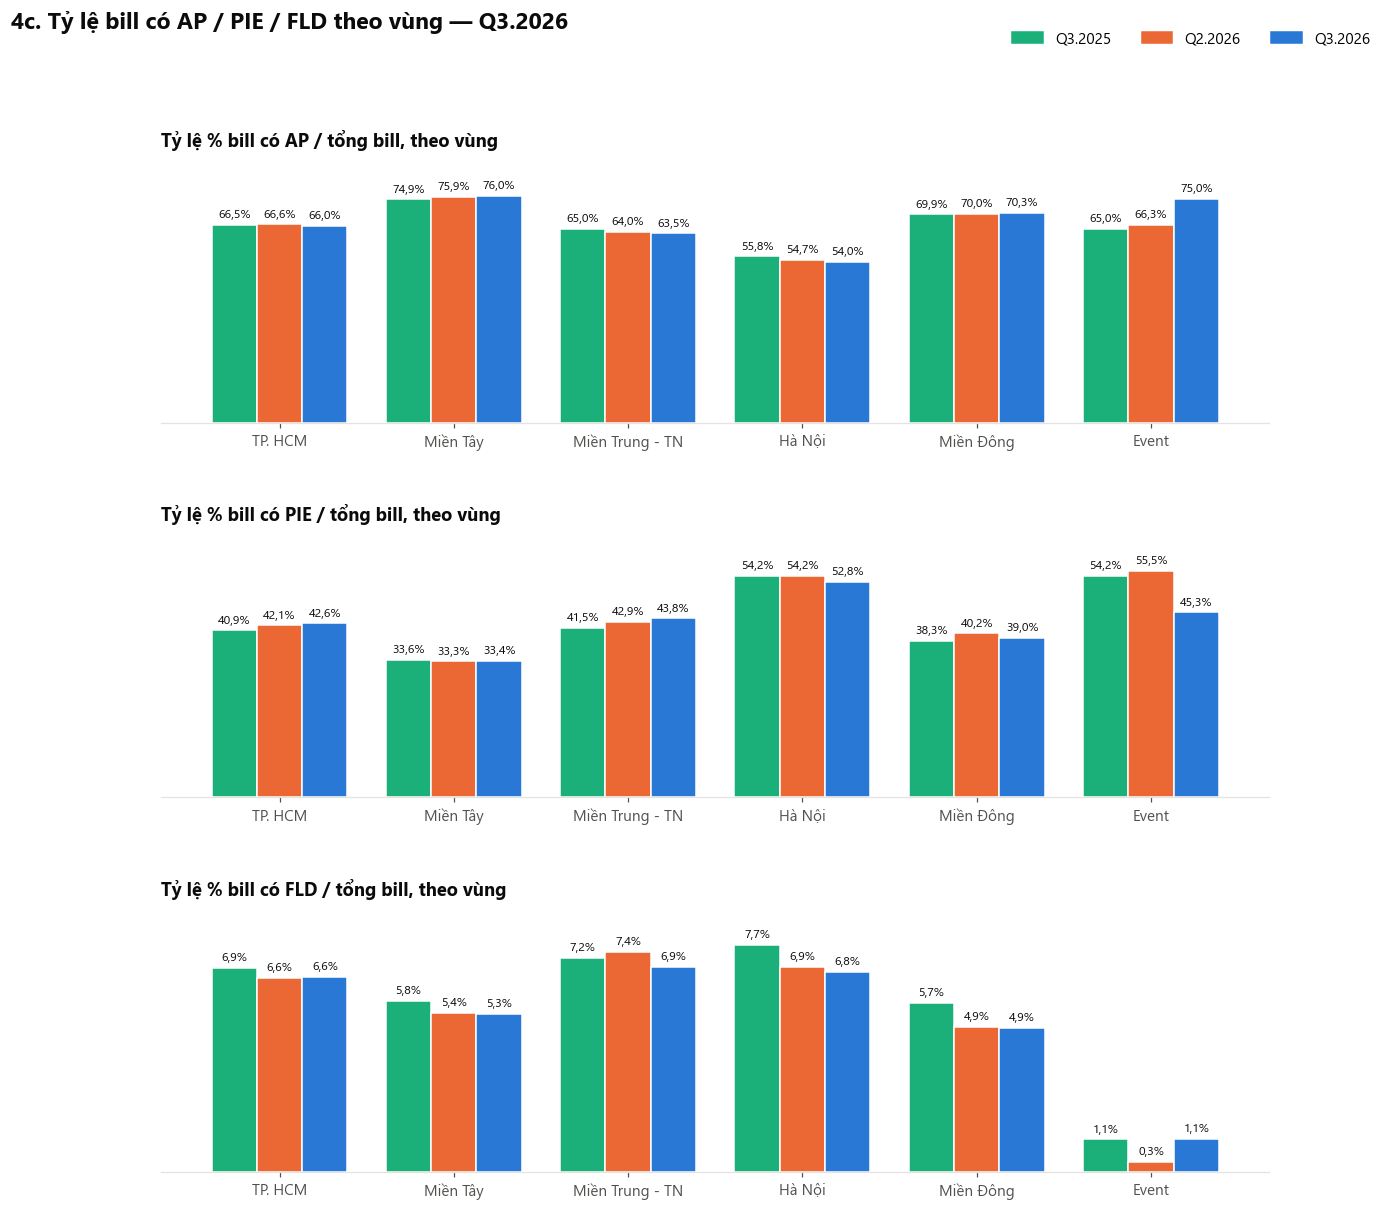

In [9]:
# AP = An Phước, AP Ladies, Gerb Weis, Tomiya... ; PIE = Pierre Cardin ; FLD = Anamai + Bonjour (đều kể cả HTT)
NHAN = ["AP", "PIE", "FLD"]
for n in NHAN:
    bills[f"Co_{n}"] = bills[f"SL_{n}"] > 0
bills["To_hop"] = bills[[f"Co_{n}" for n in NHAN]].apply(
    lambda r: " + ".join(n for n, c in zip(NHAN, r) if c) or "Khác", axis=1)
TO_HOP = ["AP", "PIE", "FLD", "AP + PIE", "AP + FLD", "PIE + FLD", "AP + PIE + FLD"]
TEN_TO_HOP = {t: ("Chỉ " + t if "+" not in t else t) for t in TO_HOP}

d4 = bills[bills["Quarter"].isin(KY_ALL)]
tong_bill = d4.groupby("Quarter").size().reindex(KY_ALL)

# Bill CÓ từng nhãn (1 bill có thể có nhiều nhãn -> cộng lại > tổng bill)
co_nhan = pd.DataFrame({f"Có {n}": d4.groupby("Quarter")[f"Co_{n}"].sum() for n in NHAN}).T.reindex(columns=KY_ALL)
ty_le_nhan = co_nhan / tong_bill * 100
tb_bill_nhan = pd.DataFrame({f"Có {n}": d4[d4[f"Co_{n}"]].groupby("Quarter")["Tongtien"].mean() for n in NHAN}).T.reindex(columns=KY_ALL)
sp_bill_nhan = pd.DataFrame({f"Có {n}": d4[d4[f"Co_{n}"]].groupby("Quarter")["SL_Ban"].mean() for n in NHAN}).T.reindex(columns=KY_ALL)

# Theo tổ hợp nhãn (mỗi bill thuộc đúng 1 tổ hợp)
so_bill_th = d4.groupby(["To_hop", "Quarter"]).size().unstack().reindex(index=TO_HOP, columns=KY_ALL).fillna(0)
ty_trong_th = so_bill_th / so_bill_th.sum() * 100
tb_bill_th = d4.groupby(["To_hop", "Quarter"])["Tongtien"].mean().unstack().reindex(index=TO_HOP, columns=KY_ALL)
sp_bill_th = d4.groupby(["To_hop", "Quarter"])["SL_Ban"].mean().unstack().reindex(index=TO_HOP, columns=KY_ALL)

ty_le_vung = {n: (d4.groupby(["Region", "Quarter"])[f"Co_{n}"].mean().unstack().reindex(columns=KY_ALL) * 100)
                 .drop(index="Không xác định", errors="ignore") for n in NHAN}
vung4 = [v for v in bills.loc[bills["Quarter"] == KY_CHINH, "Region"].value_counts().index if v in ty_le_vung["AP"].index]

print("Số bill CÓ từng nhãn:"); display(co_nhan.style.format("{:,.0f}"))
print("Tỷ lệ % bill có từng nhãn / tổng bill:"); display(ty_le_nhan.round(1))
print("Số bill theo tổ hợp nhãn:"); display(so_bill_th.rename(index=TEN_TO_HOP).style.format("{:,.0f}"))
print("Tỷ trọng % theo tổ hợp:"); display(ty_trong_th.rename(index=TEN_TO_HOP).round(1))
print("Giá trị TB bill theo tổ hợp (triệu đồng):"); display((tb_bill_th / 1e6).rename(index=TEN_TO_HOP).round(2))
print("Số sản phẩm TB / bill theo tổ hợp:"); display(sp_bill_th.rename(index=TEN_TO_HOP).round(2))


def ve_ty_le(ax, df, nhan_fmt=pct):
    # Cột giá trị (3 kỳ / nhóm), nhãn trên đầu cột
    x = np.arange(len(df)); w = 0.26
    for j, k in enumerate(KY_ALL):
        bars = ax.bar(x + (j - 1) * w, df[k], w, color=MAU[k], edgecolor="white", linewidth=1)
        for b_, v in zip(bars, df[k]):
            if not np.isnan(v):
                ax.annotate(nhan_fmt(v), (b_.get_x() + b_.get_width() / 2, v), xytext=(0, 3),
                            textcoords="offset points", ha="center", va="bottom", fontsize=8, color=INK)
    ax.set_xticks(x, df.index); ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_ylim(0, np.nanmax(df.values) * 1.18)


handles4 = [plt.Rectangle((0, 0), 1, 1, color=MAU[k]) for k in KY_ALL] + [plt.Line2D([], [], color=INK, ls="--", lw=1.2)]

# ---- 4a. Bill có từng nhãn ----
fig = plt.figure(figsize=(13, 10))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.12)
ax = fig.add_subplot(gs[0, 0]); ve_3_ky(ax, co_nhan, "So_bill"); ax.set_title("Lượt bill có từng nhãn", loc="left")
ax = fig.add_subplot(gs[0, 1]); ve_ty_le(ax, ty_le_nhan); ax.set_title("Tỷ lệ % bill có nhãn / tổng bill", loc="left")
ax = fig.add_subplot(gs[1, 0]); ve_3_ky(ax, tb_bill_nhan, "TB_bill"); ax.set_title("Giá trị TB 1 bill có nhãn (triệu đồng)", loc="left")
ax = fig.add_subplot(gs[1, 1]); ve_ty_le(ax, sp_bill_nhan, nhan_fmt=lambda v: f"{v:.2f}".replace(".", ","))
ax.set_title("Số sản phẩm TB / bill có nhãn", loc="left")
fig.legend(handles4, KY_ALL + [f"Mức {KY_CHINH}"], loc="upper right", ncol=4, frameon=False, bbox_to_anchor=(0.98, 0.985))
fig.suptitle(f"4a. Bill theo nhãn hàng AP / PIE / FLD — {KY_CHINH}", x=0.02, y=0.99, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.02, 0.948, "AP = An Phước, AP Ladies, Gerb Weis, Tomiya; PIE = Pierre Cardin; FLD = Anamai + Bonjour (kể cả HTT). "
         "1 bill có thể có nhiều nhãn.", fontsize=9.5, color=INK2)
if LUU_KET_QUA:
    fig.savefig(os.path.join(OUT_DIR, "4a_Bill_theo_nhan.png"), bbox_inches="tight", facecolor="white")
plt.show()

# ---- 4b. Theo tổ hợp nhãn trong bill ----
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 10), gridspec_kw={"hspace": 0.35})
ve_ty_le(ax1, ty_trong_th.rename(index=TEN_TO_HOP)); ax1.set_title("Tỷ trọng % lượt bill theo tổ hợp nhãn", loc="left")
ve_3_ky(ax2, tb_bill_th.rename(index=TEN_TO_HOP), "TB_bill"); ax2.set_title("Giá trị TB 1 bill theo tổ hợp nhãn (triệu đồng)", loc="left")
fig.legend(handles4, KY_ALL + [f"Mức {KY_CHINH}"], loc="upper right", ncol=4, frameon=False, bbox_to_anchor=(0.98, 0.985))
fig.suptitle(f"4b. Tổ hợp nhãn hàng trong bill — {KY_CHINH}", x=0.02, y=0.99, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.text(0.02, 0.948, "Mỗi bill thuộc đúng 1 tổ hợp (vd 'AP + PIE' = có cả hàng An Phước và Pierre Cardin, không có FLD)",
         fontsize=9.5, color=INK2)
if LUU_KET_QUA:
    fig.savefig(os.path.join(OUT_DIR, "4b_To_hop_nhan.png"), bbox_inches="tight", facecolor="white")
plt.show()

# ---- 4c. Tỷ lệ % bill có nhãn theo vùng ----
fig, axes = plt.subplots(3, 1, figsize=(13, 12), gridspec_kw={"hspace": 0.4})
for ax, n in zip(axes, NHAN):
    ve_ty_le(ax, ty_le_vung[n].reindex(vung4)); ax.set_title(f"Tỷ lệ % bill có {n} / tổng bill, theo vùng", loc="left")
fig.legend(handles4[:3], KY_ALL, loc="upper right", ncol=3, frameon=False, bbox_to_anchor=(0.98, 0.985))
fig.suptitle(f"4c. Tỷ lệ bill có AP / PIE / FLD theo vùng — {KY_CHINH}", x=0.02, y=0.99, ha="left", fontsize=15, fontweight="bold", color=INK)
if LUU_KET_QUA:
    fig.savefig(os.path.join(OUT_DIR, "4c_Ty_le_nhan_theo_vung.png"), bbox_inches="tight", facecolor="white")
plt.show()

if LUU_KET_QUA and co_the_ghi(os.path.join(OUT_DIR, f"Report_Quarter_{KY_CHINH}_Nhan_hang.xlsx")):
    with pd.ExcelWriter(os.path.join(OUT_DIR, f"Report_Quarter_{KY_CHINH}_Nhan_hang.xlsx")) as xw:
        co_nhan.to_excel(xw, sheet_name="Bill_co_nhan")
        ty_le_nhan.round(2).to_excel(xw, sheet_name="Ty_le_co_nhan_%")
        tb_bill_nhan.round(0).to_excel(xw, sheet_name="TB_bill_co_nhan")
        sp_bill_nhan.round(2).to_excel(xw, sheet_name="SP_moi_bill_co_nhan")
        so_bill_th.rename(index=TEN_TO_HOP).to_excel(xw, sheet_name="Bill_theo_to_hop")
        ty_trong_th.rename(index=TEN_TO_HOP).round(2).to_excel(xw, sheet_name="Ty_trong_to_hop_%")
        tb_bill_th.rename(index=TEN_TO_HOP).round(0).to_excel(xw, sheet_name="TB_bill_to_hop")
        sp_bill_th.rename(index=TEN_TO_HOP).round(2).to_excel(xw, sheet_name="SP_moi_bill_to_hop")
        for n in NHAN:
            ty_le_vung[n].round(2).to_excel(xw, sheet_name=f"Ty_le_{n}_vung_%")

## 5. Phân tích bill: theo ngày / thứ / khung giờ, giá trị TB, từng hiệu, tỷ lệ bill Anamai–Bonjour

Bình quân bill / ngày:


Quarter,Q3.2025,Q2.2026,Q3.2026
BQ bill/ngày,2353.0,2343.0,2268.0


Bình quân bill / ngày theo giai đoạn trong tháng:


Quarter,Q3.2025,Q2.2026,Q3.2026
Giai_doan,,,
Ngày 1–10,2384.0,2110.0,2303.0
Ngày 11–20,2294.0,2387.0,2227.0
Ngày 21–cuối,2380.0,2527.0,2275.0


Bình quân bill / ngày theo thứ:


...

Bill có từng hiệu:


So_bill  Ty_le_bill     TB_bill  TB_tien_hieu  \
Hiệu            Quarter                                                  
An Phước        Q3.2025   127895       59.07  1896408.72    1531410.51   
                Q2.2026   126332       59.24  1853319.26    1454789.80   
                Q3.2026   123735       59.29  1902984.07    1524720.75   
An Phước Ladies Q3.2025    23164       10.70  1952646.41    1308212.96   
                Q2.2026    22081       10.36  1918463.21    1223163.43   
                Q3.2026    21473       10.29  1887253.48    1223931.78   
Pierre Cardin   Q3.2025    89751       41.45  2840632.71    2648654.19   
                Q2.2026    90483       42.43  2749740.40    2505829.02   
                Q3.2026    87620       41.98  2796620.83    2573960.91   
Anamai          Q3.2025     7187        3.32  2008415.99     855410.00   
                Q2.2026     6981        3.27  2092410.21     884193.11   
                Q3.2026     7130        3.42  2025513.69     819993.73   
Bonjour         Q3.2025    10183        4.70  1685880.53     565292.49   
                Q2.2026     9277        4.35  1748787.11     562716.30   
                Q3.2026     8962        4.29  1744160.93     557590.74   

                         SP_hieu_bill  
Hiệu            Quarter                
An Phước        Q3.2025          1.64  
                Q2.2026          1.66  
                Q3.2026          1.65  
An Phước Ladies Q3.2025          1.71  
                Q2.2026          1.62  
                Q3.2026          1.73  
Pierre Cardin   Q3.2025          1.56  
                Q2.2026          1.57  
                Q3.2026          1.54  
Anamai          Q3.2025          1.80  
                Q2.2026          1.78  
                Q3.2026          1.81  
Bonjour         Q3.2025          2.20  
                Q2.2026          2.04  
                Q3.2026          2.08

Bill có Anamai / Bonjour (số bill và % trên tổng bill):


,Q3.2025 | Số bill,Q3.2025 | % tổng bill,Q2.2026 | Số bill,Q2.2026 | % tổng bill,Q3.2026 | Số bill,Q3.2026 | % tổng bill
Anamai hoặc Bonjour,"14,000",6.47%,"13,104",6.15%,"12,731",6.10%
Có Anamai,"7,187",3.32%,"6,981",3.27%,"7,130",3.42%
Có Bonjour,"10,183",4.70%,"9,277",4.35%,"8,962",4.29%
Có cả Anamai + Bonjour,"3,370",1.56%,"3,154",1.48%,"3,361",1.61%
Tổng bill,"216,503",100.00%,"213,237",100.00%,"208,699",100.00%


5 ngày đông nhất Q3.2026: 02/09 (Thứ 4), 28/08 (Thứ 6), 27/08 (Thứ 5), 29/08 (Thứ 7), 01/09 (Thứ 3)
5 ngày vắng nhất Q3.2026: 22/09 (Thứ 3), 23/09 (Thứ 4), 21/09 (Thứ 2), 13/07 (Thứ 2), 03/08 (Thứ 2)


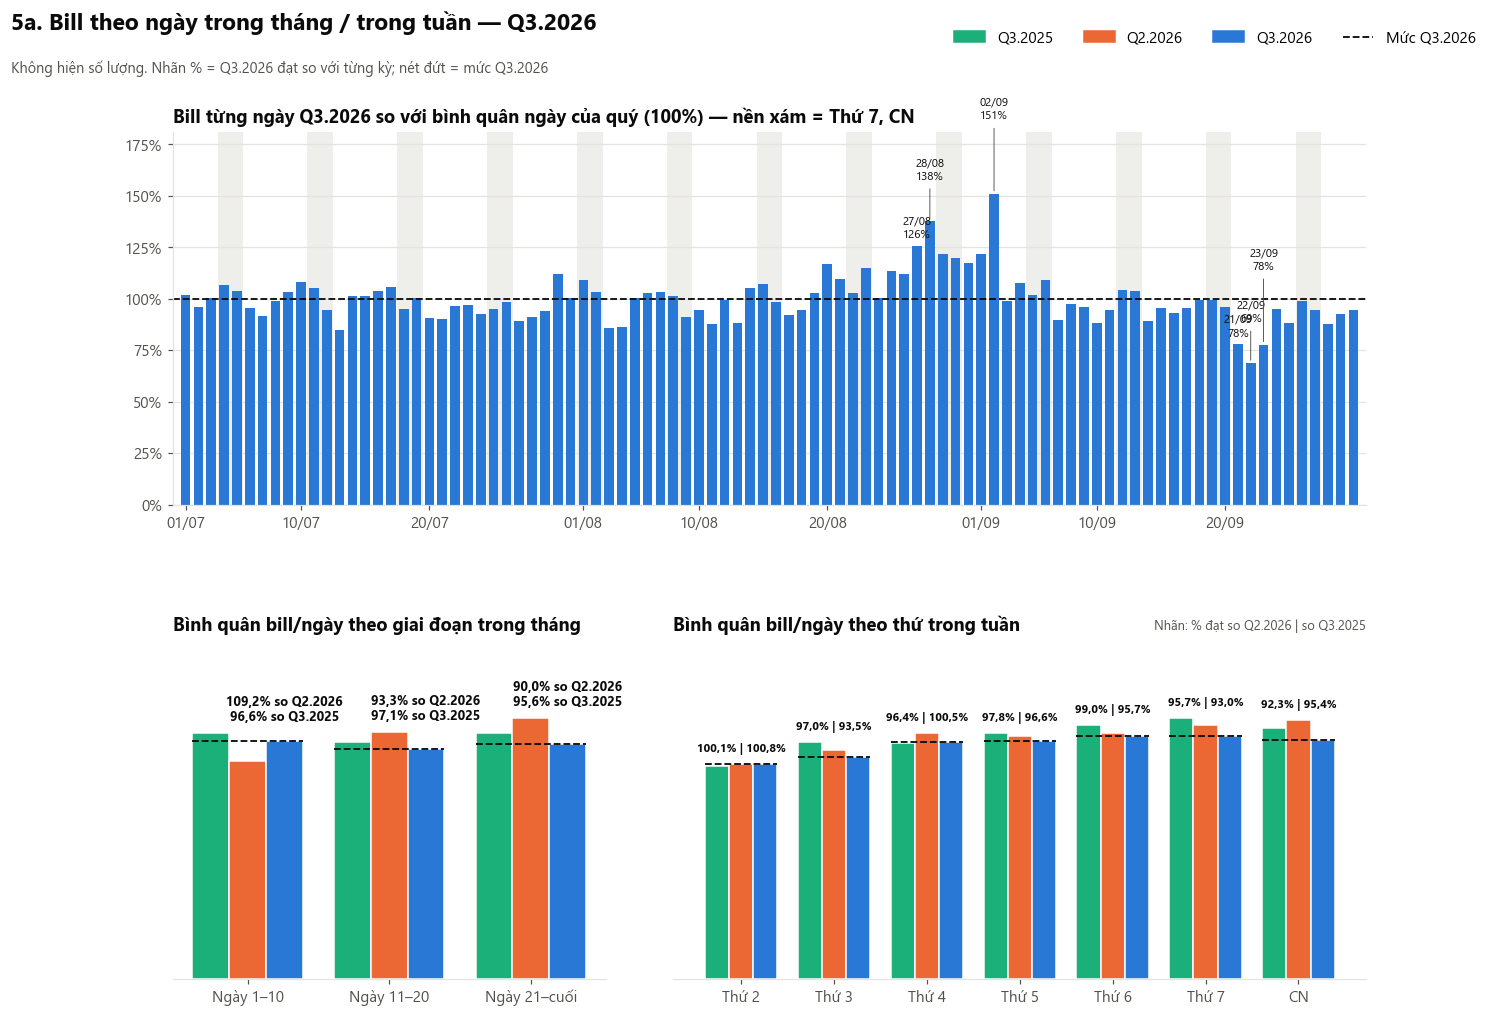

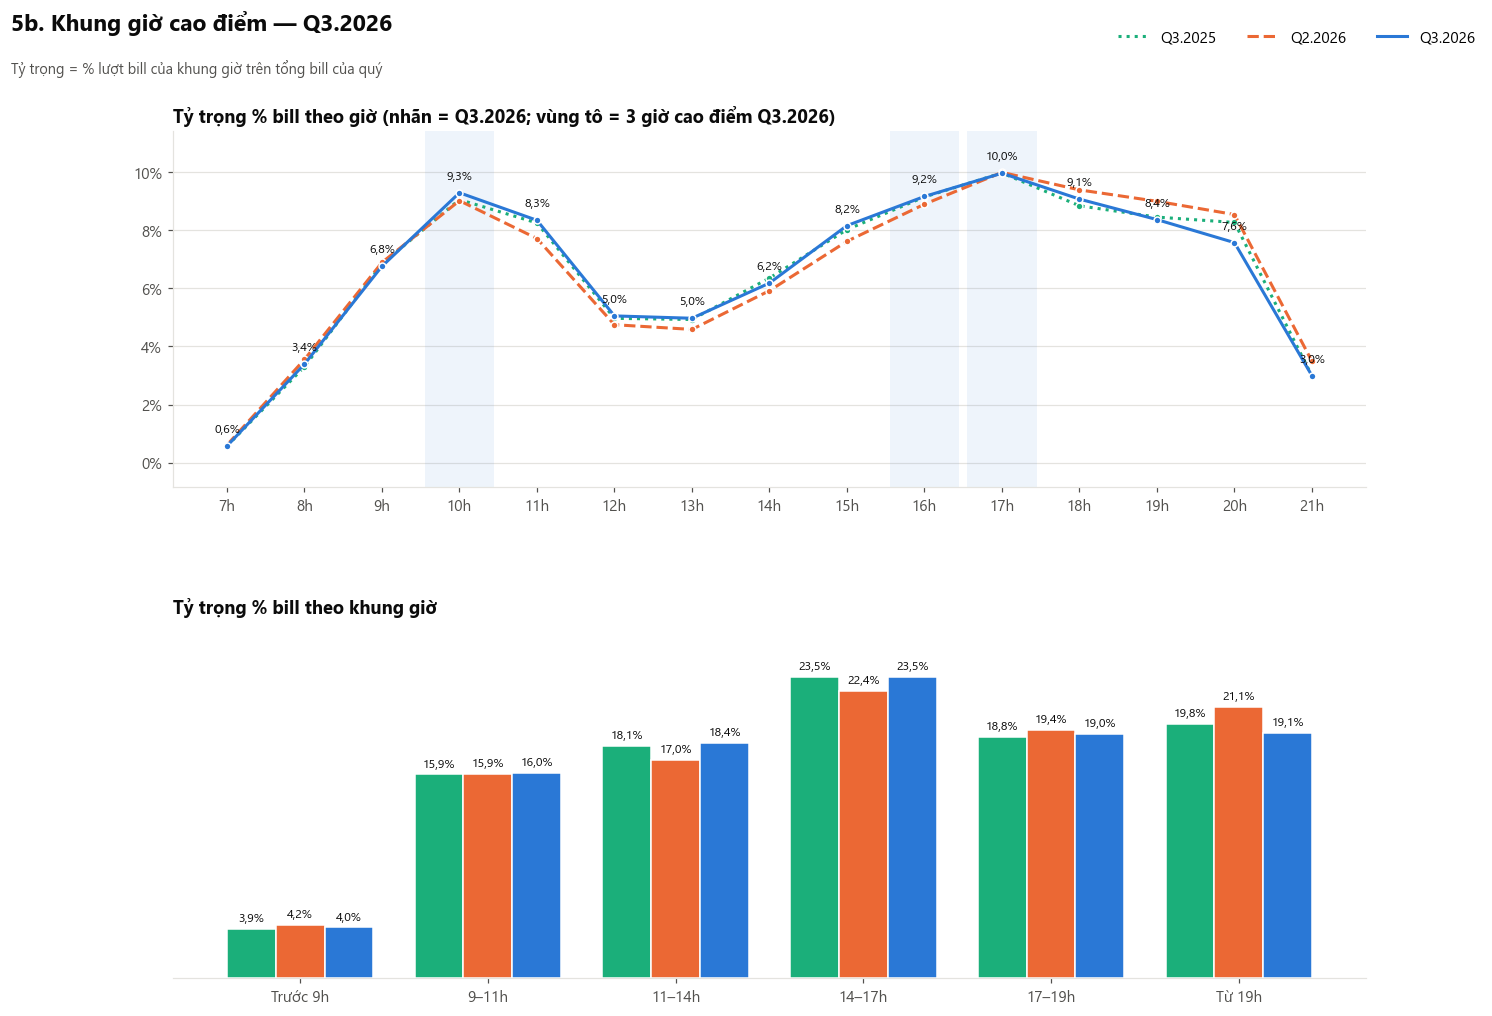

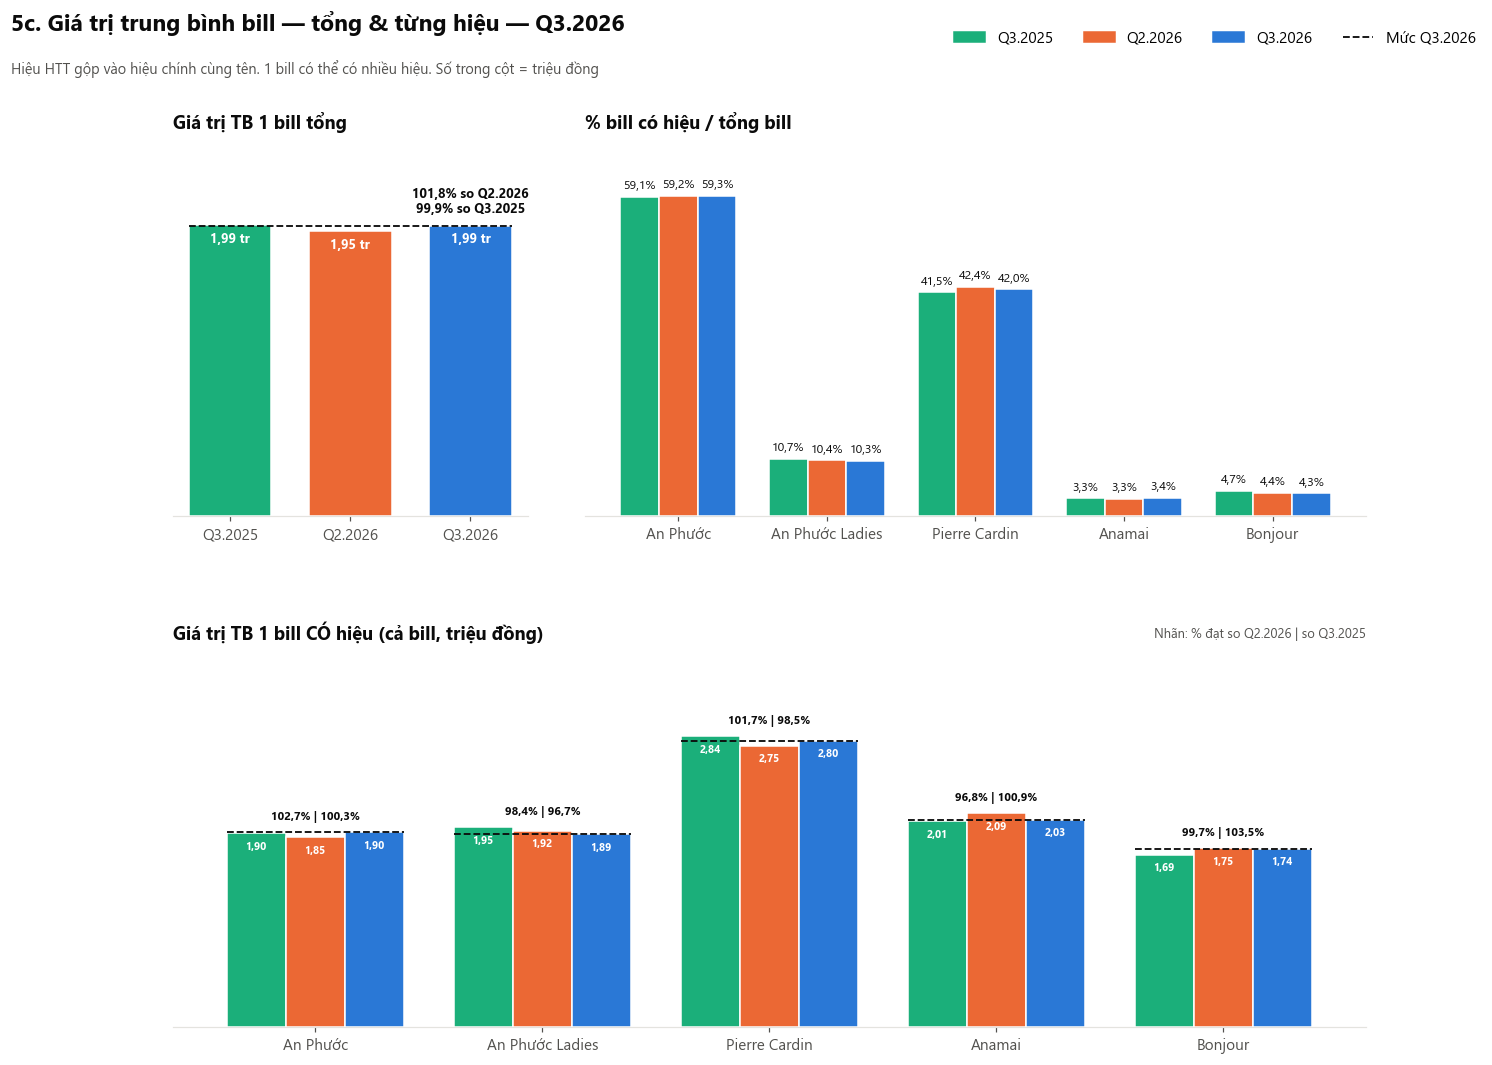

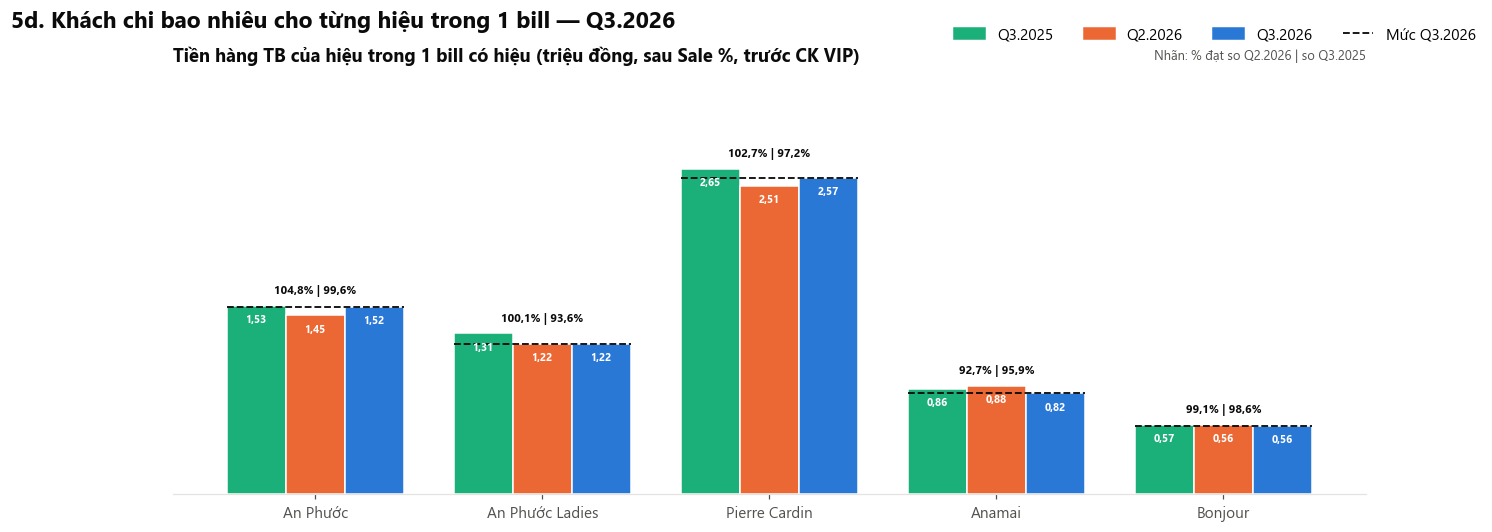

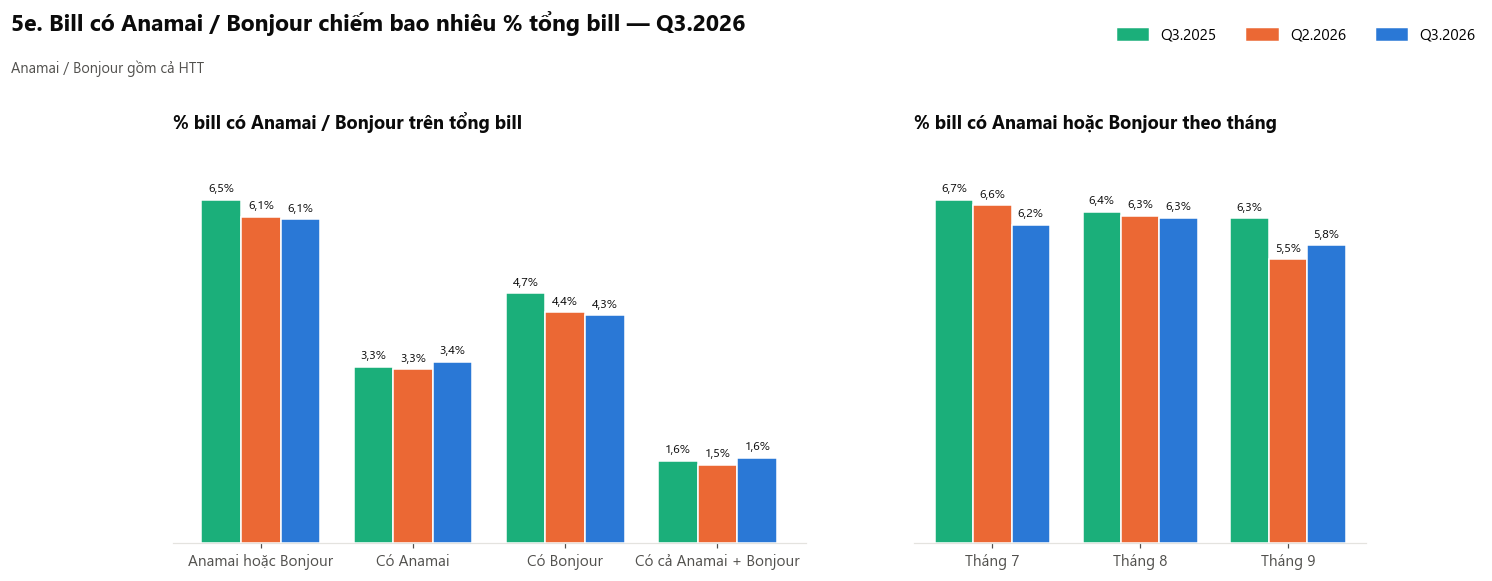

In [10]:
d5 = bills[bills["Quarter"].isin(KY_ALL)].copy()
TEN_HIEU = {m: t for m, t in qb.HIEU.items() if m != "KHAC"}

# ---------- Số bill theo ngày ----------
bill_ngay = d5.groupby(["Quarter", "Ngay"]).size().rename("So_bill").reset_index()
bill_ngay["Ngay_trong_thang"] = bill_ngay["Ngay"].dt.day
bill_ngay["Giai_doan"] = pd.cut(bill_ngay["Ngay_trong_thang"], [0, 10, 20, 31], labels=["Ngày 1–10", "Ngày 11–20", "Ngày 21–cuối"])
bill_ngay["Thu"] = bill_ngay["Ngay"].dt.dayofweek
bq_ngay = bill_ngay.groupby("Quarter")["So_bill"].mean().reindex(KY_ALL)                  # bình quân bill / ngày
bq_giai_doan = bill_ngay.groupby(["Giai_doan", "Quarter"], observed=True)["So_bill"].mean().unstack().reindex(columns=KY_ALL)
bq_thu = bill_ngay.groupby(["Thu", "Quarter"])["So_bill"].mean().unstack().reindex(columns=KY_ALL).rename(index=dict(enumerate(qb.THU_VN)))

# ---------- Khung giờ ----------
KHUNG = ["Trước 9h", "9–11h", "11–14h", "14–17h", "17–19h", "Từ 19h"]
d5["Khung_gio"] = pd.cut(d5["Gio"], [0, 9, 11, 14, 17, 19, 24], right=False, labels=KHUNG)
ty_trong_khung = d5.groupby(["Khung_gio", "Quarter"], observed=True).size().unstack().reindex(columns=KY_ALL)
ty_trong_khung = ty_trong_khung / ty_trong_khung.sum() * 100
ty_trong_gio5 = d5.groupby(["Gio", "Quarter"]).size().unstack().reindex(columns=KY_ALL)
ty_trong_gio5 = ty_trong_gio5 / ty_trong_gio5.sum() * 100
ty_trong_gio5 = ty_trong_gio5[ty_trong_gio5.max(axis=1) >= 0.3]

# ---------- Giá trị TB bill & từng hiệu ----------
tb_tong = d5.groupby("Quarter").agg(TB_bill=("Tongtien", "mean"), SP_bill=("SL_Ban", "mean")).T.reindex(columns=KY_ALL)
tong_bill5 = d5.groupby("Quarter").size().reindex(KY_ALL)
hieu_rows = {}
for m, ten in TEN_HIEU.items():
    co = d5[d5[f"SLH_{m}"] > 0].groupby("Quarter")
    hieu_rows[ten] = pd.DataFrame({
        "So_bill": co.size(), "Ty_le_bill": co.size() / tong_bill5 * 100,
        "TB_bill": co["Tongtien"].mean(), "TB_tien_hieu": co[f"TTH_{m}"].mean(), "SP_hieu_bill": co[f"SLH_{m}"].mean(),
    }).reindex(KY_ALL)
hieu = pd.concat(hieu_rows, names=["Hiệu", "Quarter"])
lay = lambda col: hieu[col].unstack().reindex(columns=KY_ALL).reindex(list(TEN_HIEU.values()))

# ---------- Bill có Anamai / Bonjour ----------
co_ana, co_bon = d5["SLH_ANA"] > 0, d5["SLH_BON"] > 0
nhom_fld = pd.DataFrame({"Anamai hoặc Bonjour": co_ana | co_bon, "Có Anamai": co_ana, "Có Bonjour": co_bon,
                         "Có cả Anamai + Bonjour": co_ana & co_bon, "Quarter": d5["Quarter"]})
so_bill_fld = nhom_fld.groupby("Quarter").sum().T.reindex(columns=KY_ALL)
ty_le_fld = so_bill_fld / tong_bill5 * 100
# Bảng gộp: số bill + % trên tổng bill từng kỳ, có dòng Tổng bill để đối chiếu
_so = pd.concat([so_bill_fld, tong_bill5.to_frame("Tổng bill").T])
_tl = _so / tong_bill5 * 100
bang_fld = pd.DataFrame({f"{k} | {c}": (_so[k] if c == "Số bill" else _tl[k].round(2))
                         for k in KY_ALL for c in ("Số bill", "% tổng bill")})
thang_chinh5 = {i: m for i, (_, m) in enumerate(qb.quarter_months(KY_CHINH), 1)}
ty_le_fld_thang = (nhom_fld.assign(T=d5["Thang_trong_quy"]).groupby(["T", "Quarter"])["Anamai hoặc Bonjour"].mean()
                   .unstack().reindex(columns=KY_ALL) * 100).rename(index=lambda i: f"Tháng {thang_chinh5[i]}")

print("Bình quân bill / ngày:"); display(bq_ngay.round(0).to_frame("BQ bill/ngày").T)
print("Bình quân bill / ngày theo giai đoạn trong tháng:"); display(bq_giai_doan.round(0))
print("Bình quân bill / ngày theo thứ:"); display(bq_thu.round(0))
print("Tỷ trọng % bill theo khung giờ:"); display(ty_trong_khung.round(1))
print("Giá trị TB bill & số SP / bill:"); display(tb_tong.round(2))
print("Bill có từng hiệu:"); display(hieu.round(2))
print("Bill có Anamai / Bonjour (số bill và % trên tổng bill):")
display(bang_fld.style.format({c: ("{:,.0f}" if "Số bill" in c else "{:.2f}%") for c in bang_fld.columns}))
q = bill_ngay[bill_ngay["Quarter"] == KY_CHINH].sort_values("So_bill")
print(f"5 ngày đông nhất {KY_CHINH}:", ", ".join(f"{d:%d/%m} ({qb.THU_VN[d.dayofweek]})" for d in q.tail(5)["Ngay"][::-1]))
print(f"5 ngày vắng nhất {KY_CHINH}:", ", ".join(f"{d:%d/%m} ({qb.THU_VN[d.dayofweek]})" for d in q.head(5)["Ngay"]))

so_le = lambda v: f"{v:.2f}".replace(".", ",")
luu = lambda fig, ten: fig.savefig(os.path.join(OUT_DIR, ten), bbox_inches="tight", facecolor="white") if LUU_KET_QUA else None
def tieu_de(fig, tieu, mo_ta, legend=True):
    if legend:
        fig.legend(handles4, KY_ALL + [f"Mức {KY_CHINH}"], loc="upper right", ncol=4, frameon=False, bbox_to_anchor=(0.98, 0.985))
    fig.suptitle(tieu, x=0.02, y=0.99, ha="left", fontsize=15, fontweight="bold", color=INK)
    fig.text(0.02, 0.99 - 0.45 / fig.get_figheight(), mo_ta, fontsize=9.5, color=INK2, va="top")

# ---- 5a. Bill theo ngày ----
fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1.1, 1], width_ratios=[1, 1.6], hspace=0.38, wspace=0.12)
ax = fig.add_subplot(gs[0, :])
q = bill_ngay[bill_ngay["Quarter"] == KY_CHINH].sort_values("Ngay").reset_index(drop=True)
chi_so_ngay = q["So_bill"] / q["So_bill"].mean() * 100
cuoi_tuan = q["Thu"] >= 5
for i in q.index[cuoi_tuan]:
    ax.axvspan(i - 0.5, i + 0.5, color=GRID, alpha=0.6, lw=0)
ax.bar(q.index, chi_so_ngay, 0.75, color=MAU[KY_CHINH])
ax.axhline(100, color=INK, lw=1.2, ls="--")
for j, i in enumerate(sorted(list(chi_so_ngay.nlargest(3).index) + list(chi_so_ngay.nsmallest(3).index))):
    # so le độ cao nhãn để các ngày liền nhau không đè lên nhau
    ax.annotate(f"{q.loc[i, 'Ngay']:%d/%m}\n{pct(chi_so_ngay[i], 0)}", (i, chi_so_ngay[i]), xytext=(0, 3 + 22 * (j % 3)),
                textcoords="offset points", ha="center", va="bottom", fontsize=7.5, color=INK,
                arrowprops=dict(arrowstyle="-", color=INK2, lw=0.6) if j % 3 else None)
dau_thang = q.index[q["Ngay"].dt.day.isin([1, 10, 20])]
ax.set_xticks(dau_thang, [f"{d:%d/%m}" for d in q.loc[dau_thang, "Ngay"]])
ax.set_ylim(0, chi_so_ngay.max() * 1.2); ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.grid(axis="y", color=GRID); ax.set_axisbelow(True); ax.set_xlim(-1, len(q))
ax.set_title(f"Bill từng ngày {KY_CHINH} so với bình quân ngày của quý (100%) — nền xám = Thứ 7, CN", loc="left")
ax = fig.add_subplot(gs[1, 0]); ve_3_ky(ax, bq_giai_doan, "So_bill"); ax.set_title("Bình quân bill/ngày theo giai đoạn trong tháng", loc="left")
ax = fig.add_subplot(gs[1, 1]); ve_3_ky(ax, bq_thu, "So_bill"); ax.set_title("Bình quân bill/ngày theo thứ trong tuần", loc="left")
tieu_de(fig, f"5a. Bill theo ngày trong tháng / trong tuần — {KY_CHINH}",
        f"Không hiện số lượng. Nhãn % = {KY_CHINH} đạt so với từng kỳ; nét đứt = mức {KY_CHINH}")
luu(fig, "5a_Bill_theo_ngay_tuan.png"); plt.show()

# ---- 5b. Khung giờ cao điểm ----
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={"hspace": 0.38})
x = np.arange(len(ty_trong_gio5))
for i in [list(ty_trong_gio5.index).index(h) for h in ty_trong_gio5[KY_CHINH].nlargest(3).index]:
    ax1.axvspan(i - 0.45, i + 0.45, color=MAU[KY_CHINH], alpha=0.08, lw=0)
for k, ls in zip(KY_ALL, (":", "--", "-")):
    ax1.plot(x, ty_trong_gio5[k], ls, color=MAU[k], lw=2, marker="o", ms=4.5, markeredgecolor="white", markeredgewidth=1)
for xi, v in zip(x, ty_trong_gio5[KY_CHINH]):
    ax1.annotate(pct(v), (xi, v), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8, color=INK)
ax1.set_xticks(x, [f"{h}h" for h in ty_trong_gio5.index]); ax1.margins(y=0.15)
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.0f}%")); ax1.grid(axis="y", color=GRID); ax1.set_axisbelow(True)
ax1.set_title(f"Tỷ trọng % bill theo giờ (nhãn = {KY_CHINH}; vùng tô = 3 giờ cao điểm {KY_CHINH})", loc="left")
ve_ty_le(ax2, ty_trong_khung); ax2.set_title("Tỷ trọng % bill theo khung giờ", loc="left")
tieu_de(fig, f"5b. Khung giờ cao điểm — {KY_CHINH}", "Tỷ trọng = % lượt bill của khung giờ trên tổng bill của quý", legend=False)
fig.legend([plt.Line2D([], [], color=MAU[k], ls=ls, lw=2) for k, ls in zip(KY_ALL, (":", "--", "-"))], KY_ALL,
           loc="upper right", ncol=3, frameon=False, bbox_to_anchor=(0.98, 0.985))
luu(fig, "5b_Khung_gio_cao_diem.png"); plt.show()

# ---- 5c. Giá trị TB bill tổng & từng hiệu ----
fig = plt.figure(figsize=(14, 10.5))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2.2], hspace=0.35, wspace=0.1)
ax = fig.add_subplot(gs[0, 0]); ve_3_ky(ax, tb_tong.loc[["TB_bill"]].rename(index={"TB_bill": "Toàn hệ thống"}), "TB_bill", w=0.22, step=0.32)
ax.set_xticks([(j - 1) * 0.32 for j in range(3)], KY_ALL); ax.set_title("Giá trị TB 1 bill tổng", loc="left")
ax = fig.add_subplot(gs[0, 1]); ve_ty_le(ax, lay("Ty_le_bill")); ax.set_title("% bill có hiệu / tổng bill", loc="left")
ax = fig.add_subplot(gs[1, :]); ve_3_ky(ax, lay("TB_bill"), "TB_bill")
ax.set_title("Giá trị TB 1 bill CÓ hiệu (cả bill, triệu đồng)", loc="left")
tieu_de(fig, f"5c. Giá trị trung bình bill — tổng & từng hiệu — {KY_CHINH}",
        "Hiệu HTT gộp vào hiệu chính cùng tên. 1 bill có thể có nhiều hiệu. Số trong cột = triệu đồng")
luu(fig, "5c_TB_bill_tung_hieu.png"); plt.show()

fig, ax = plt.subplots(figsize=(14, 5))
ve_3_ky(ax, lay("TB_tien_hieu"), "TB_bill")
ax.set_title("Tiền hàng TB của hiệu trong 1 bill có hiệu (triệu đồng, sau Sale %, trước CK VIP)", loc="left")
tieu_de(fig, f"5d. Khách chi bao nhiêu cho từng hiệu trong 1 bill — {KY_CHINH}", "")
luu(fig, "5d_Tien_hieu_moi_bill.png"); plt.show()

# ---- 5e. Bill có Anamai / Bonjour ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), width_ratios=[1.4, 1])
ve_ty_le(ax1, ty_le_fld); ax1.set_title("% bill có Anamai / Bonjour trên tổng bill", loc="left")
ve_ty_le(ax2, ty_le_fld_thang); ax2.set_title("% bill có Anamai hoặc Bonjour theo tháng", loc="left")
tieu_de(fig, f"5e. Bill có Anamai / Bonjour chiếm bao nhiêu % tổng bill — {KY_CHINH}",
        "Anamai / Bonjour gồm cả HTT", legend=False)
fig.legend(handles4[:3], KY_ALL, loc="upper right", ncol=3, frameon=False, bbox_to_anchor=(0.98, 0.985))
fig.subplots_adjust(top=0.78)
luu(fig, "5e_Ty_le_bill_Anamai_Bonjour.png"); plt.show()

if LUU_KET_QUA:
    with pd.ExcelWriter(os.path.join(OUT_DIR, f"Report_Quarter_{KY_CHINH}_Phan_tich_bill.xlsx")) as xw:
        bill_ngay.pivot(index="Ngay", columns="Quarter", values="So_bill").to_excel(xw, sheet_name="Bill_tung_ngay")
        bq_ngay.round(1).to_frame("BQ_bill_ngay").to_excel(xw, sheet_name="BQ_bill_ngay")
        bq_giai_doan.round(1).to_excel(xw, sheet_name="BQ_ngay_giai_doan")
        bq_thu.round(1).to_excel(xw, sheet_name="BQ_ngay_theo_thu")
        ty_trong_gio5.round(2).to_excel(xw, sheet_name="Ty_trong_gio_%")
        ty_trong_khung.round(2).to_excel(xw, sheet_name="Ty_trong_khung_gio_%")
        tb_tong.round(2).to_excel(xw, sheet_name="TB_bill_tong")
        hieu.round(2).to_excel(xw, sheet_name="Tung_hieu")
        bang_fld.to_excel(xw, sheet_name="Bill_Anamai_Bonjour")
        ty_le_fld_thang.round(2).to_excel(xw, sheet_name="Ty_le_FLD_thang_%")

## Xuất Excel

In [11]:
path = os.path.join(OUT_DIR, f"Report_Quarter_{KY_CHINH}.xlsx")
if LUU_KET_QUA and co_the_ghi(path):
    with pd.ExcelWriter(path) as xw:
        tom_tat.to_excel(xw, sheet_name="Tom_tat", index=False)
        tong.to_excel(xw, sheet_name="Tong_theo_quy")
        for m, ten in (("So_bill", "Bill"), ("TB_bill", "TB_bill")):
            pd.DataFrame({f"vs {k}": so_sanh(m, k, by="Region") for k in (KY_TRUOC, CUNG_KY)}).round(1) \
              .to_excel(xw, sheet_name=f"{ten}_theo_vung_%")
            pd.DataFrame({f"vs {k}": so_sanh(m, k, by="Store_name") for k in (KY_TRUOC, CUNG_KY)}).round(1) \
              .to_excel(xw, sheet_name=f"{ten}_theo_CH_%")
        tt_gio.round(2).to_excel(xw, sheet_name="Ty_trong_gio_%")
        tt_thu.rename(index=dict(enumerate(qb.THU_VN))).round(2).to_excel(xw, sheet_name="Ty_trong_thu_%")
        for k in KY3:
            hm[k].rename(index=dict(enumerate(qb.THU_VN))).round(2).to_excel(xw, sheet_name=f"Thu_x_Gio_{k}")
    print("Đã lưu:", path)

Đã lưu: D:\AnPhuocGroup\AnPhuoc_Data\01.Python_Projects\04.Output\Report_Quarter\Q3.2026\Report_Quarter_Q3.2026.xlsx
